# Environmental Footprints of Housing
This code calculates environmental footprints of housing under a given set of energy use, energy technology, housing size of different building types, and transport use in relation to building type, cohort, location and income or tenure.

For the analysis of current housing in NL the following datasets are needed:
- Set of assumptions: CBS microdata output
- Material use per building types and cohorts
- Emission factors per pkm, kg, kWh, solar PV capacity, heat pump

In [ ]:
# data processing modules
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer # used for imputation of missing mobility behaviour data
import re

# data visualisation modules
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches

# Display options
pd.options.display.float_format = '{:,.2f}'.format #limits printed decimal points to two
#pd.reset_option('^display.', silent=True) #option to reset the previous display option

### Set of Assumptions
- configure assumptions
- import the CBS file

In [ ]:
# Configurations
scenario = 'current'
#scenario = 'Boekel'
#scenario = 'Iewan'
#scenario = "Kavel_Z1"
#scenario = "dNM"
year = '2023' #alternative: '2019', '2023'
year_scenario = '2030' #alternative: '2030', '2040', '2050'
age_group = ''  #alternative: '' means all ages of household heads; '_age1864' means household heads are aged 18-64 i.e. working age population, '_incclass' for income levels in four classes including top1%
classification = 'tenure' #alternative: 'tenure', 'income'
if classification == 'income':
    lab = 'inc_lab'
    class_name = 'income level'
    class_name_short = 'income'
    class_name_long = 'income level'
    if age_group == '_incclass':
        inc_grouping = 'top1deciles' #alternative: '' predefined groups or deciles, 'top1deciles' replaces decile 10 (richest) by top 1% and 90-99%
        class_col = 'inc_decile' #'inc_class'+year
    else:
        inc_grouping = ''
        class_col = 'inc_decile'
else: #if tenure
    lab = 'tenure_lab'
    class_name = 'tenure'
    class_name_short = 'tenure'
    class_name_long = 'tenure'
    class_col = str('tenure'+year)
    inc_grouping = ''
material_buildings_source = 'Oorschot-MPG'
ghg_pkm_source = 'Milieucentraal' #alternative: 'Milieucentraal' assumes average cars in NL, 'Milieucentraal - e-car' assumes all cars to be e-cars
ghg_districtheating_source = 'BONSAI' #alternative: 'BONSAI' assumes roughly 1.5 the emission intensity of 'Verhagen', 'Herberigs' assumes 1.4 times emission intensity of Verhagen

valid_scenarios = {'current', 'Boekel', 'Iewan', 'Kavel_Z1', 'dNM'}

# File import: all scenarios use the CBS baseline for comparison and column definitions.
if scenario in valid_scenarios:
    if inc_grouping == 'top1deciles':
        use = pd.read_excel(
                    "data_input/output/"+class_name_short+" typology construction density distance privacy "+year+".xlsx",
                    index_col=[0,1,2,3,4],
                    header=[0],
                    )
        use.drop('decile 10 (richest)',axis=0, level=0, inplace=True)
                
        use_top1 = pd.read_excel(
                    "data_input/output/"+class_name_short+" typology construction density distance privacy "+year+age_group+".xlsx",
                    index_col=[0,1,2,3,4],
                    header=[0],
                    )
        use_top1.rename(columns={'inc_class'+year: 'inc_decile'}, inplace=True)
        use_top1.drop(['51-90%', 'poorest 50%'],axis=0, level=0, inplace=True)
        use_top1.rename(index={'91-99%':'percentile 91-99%', 'top 1%':'top 1% (richest)'}, inplace=True)

        use_top1.replace({'inc_decile': 4}, {'inc_decile': 11}, inplace=True)
        use_top1.replace({'inc_decile': 3}, {'inc_decile': 10}, inplace=True)
        use = pd.concat([use, use_top1])

        mobility = pd.read_excel(
                        "data_input/output/"+class_name_short+" density distance privacy odin "+year+".xlsx",
                        index_col=[0,1,2],
                        header=[0],
                        )
        mobility.drop('decile 10 (richest)',axis=0, level=0, inplace=True)
                
        mobility_top1 = pd.read_excel(
                        "data_input/output/"+class_name_short+" density distance privacy odin "+year+age_group+".xlsx",
                        index_col=[0,1,2],
                        header=[0],
                        )
        mobility_top1.rename(columns={'inc_class'+year: 'inc_decile'}, inplace=True)
        mobility_top1.drop(['51-90%', 'poorest 50%'],axis=0, level=0, inplace=True)
        mobility_top1.rename(index={'91-99%':'percentile 91-99%', 'top 1%':'top 1% (richest)'}, inplace=True)

        mobility_top1.replace({'inc_decile': 4}, {'inc_decile': 11}, inplace=True)
        mobility_top1.replace({'inc_decile': 3}, {'inc_decile': 10}, inplace=True)

        mobility = pd.concat([mobility, mobility_top1])
    else:
        use = pd.read_excel(
            "data_input/output/"+class_name_short+" typology construction density distance privacy "+year+age_group+".xlsx",
            index_col=[0,1,2,3,4],
            header=[0],
        )

        mobility = pd.read_excel(
                "data_input/output/"+class_name_short+" density distance privacy odin "+year+age_group+".xlsx",
                index_col=[0,1,2],
                header=[0],
            )
    
    #fill missing information for small sample observations with average value
    mobility.loc[mobility['n_hhd_uw'].notna()] = mobility.loc[mobility['n_hhd_uw'].notna()].fillna(5)

    # add transport use and vehicles per household to other variables, assumption: households with similar income, surrounding population density and distance to train station show similar mobility behaviour irrespective of building type or building age
    use_pkm = mobility['dist_carpp_py'] / mobility['n_hhd']#pkm per year per household
    use_pkm.name = 'car_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_vkm = mobility['dist_car_py'] / mobility['n_hhd']#pkm per year per household
    use_vkm.name = 'car_vkm'
    use = use.join(use_vkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_transit_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'transit_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_walk_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'walk_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_cycle_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'cycle_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['car_hhd'] / mobility['n_hhd_uw'] #cars per household
    use_pkm.name = 'car_hhd'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    #weighting the pkm depending on number of adults in household i.e. more pkm allocated to households with more adults, less to households with fewer adults
    use_cap_per_hhd_mean = (use['n_adultmem'+year].groupby(level=[0,3,4], sort=False).sum()/use['n_hhd'].groupby(level=[0,3,4], sort=False).sum()) 
    use_cap_per_hhd_mean.name = 'n_mem_per_hhd_mobility'
    use = use.join(use_cap_per_hhd_mean, on=[lab,'density_lab', 'distance_train_lab'])
    use['mem_weight'] = (use['n_adultmem'+year]/use['n_hhd'])/use['n_mem_per_hhd_mobility']

    for i in ['car_pkm', 'car_vkm', 'transit_pkm', 'walk_pkm', 'cycle_pkm','car_hhd']:
        use[i] = use[i]*use['mem_weight']
    
    #removing entries where no observations in use dataset
    use.loc[use['size'+year+'_w1'].isna(), 'car_vkm'] = np.nan
    use.loc[use['size'+year+'_w1'].isna(), 'n_mem_per_hhd_mobility'] = np.nan

    #impute entries where no observations of mobility behaviour (low income+rural+close to train station) roughly 0.1% of population
    index_cols = [class_col, 'typology4_'+year, 'const_cat'+year, 'density'+year,
       'q_distance_train'+year]
    mobility_cols = ['car_pkm', 'car_vkm', 'transit_pkm', 'walk_pkm',
        'cycle_pkm', 'car_hhd']
    pred_cols = ['distance_depstore'+year, 'distance_supermarket'+year, 'distance_middleschool'+year, 'mean_hhd', 'mean_adult']
    df = use.loc[use['n_hhd'].notna(), index_cols+pred_cols+mobility_cols]
    use_imputed = pd.DataFrame(KNNImputer(missing_values=np.nan, n_neighbors=3, weights='distance').fit(df).transform(df), index=df.index, columns=df.columns)
    use.update(use_imputed)

    #change index labels to create more readable graphs
    use = use.rename(index={'detached (vrijstaand)':'detached', 'multiple fam (meergezins)':'multifamily', 'row house (tussenwoning)':'row house', 'semi-detached (2-1 kap) / corner (hoek)':'semi-detached'}, level=1)
    use = use.rename(index={'priate rental':'private rental'}, level=0)

    


# Function to relabel income deciles
def group_deciles(label):
    s = str(label)
    if "decile" in s:
        m = re.search(r"(\d+)", s)
        if m:
            d = int(m.group(1))
            if d == 1:
                return "decile 1 (poorest)"
            elif d in (2, 3):
                return "decile 2"
            elif d in (4, 5):
                return "decile 3"
            elif d == 6:
                return "decile 4"
            elif d in (7, 8, 9, 10):
                return "decile 5 (richest)"
    return label

# Relabel once, after baseline joins and imputation. This does not aggregate rows.
if classification == "income":
    use = use.rename(index=group_deciles, level="inc_lab")

# Export the baseline with the same labels used in this run.
use.to_csv('data_input/output/use'+class_name_short+year+age_group+inc_grouping+'.csv')

# Create only the selected archetype; preserve downstream variable names.
if scenario == "Boekel":
    # --- Step 1: Define Boekel parameters ---
    boekel_income_groups = [
        "decile 1 (poorest)",
        "decile 2",
        #"decile 3",
        #"decile 4",
    ]
    
    # --- Step 2: Define index names consistent with 'use' ---
    index_names = ['inc_lab', 'typology_lab', 'const_lab', 'density_lab', 'distance_train_lab']
    
    # --- Step 3: Create MultiIndex for Boekel rows ---
    boekel_index = pd.MultiIndex.from_product(
        [boekel_income_groups, ['row house'], ['2006-2022'], ['low suburban'], ['Boekel']],
        names=index_names
    )

    # --- Step 4: Create empty DataFrame with same columns and dtypes as 'use' ---
    boekel_df = pd.DataFrame(
        np.nan,
        index=boekel_index,
        columns=use.columns
    )

    # Match data types for numeric columns
    for col in use.columns:
        if col in boekel_df.columns:
            boekel_df[col] = boekel_df[col].astype(use[col].dtype, errors='ignore')

    # --- Step 5: Define mapping for household members per income decile ---
    hhdmem_mapping = {
        "decile 1 (poorest)": 1,
        "decile 2": 1,
        #"decile 3": 2,
        #"decile 4": 2,
    }

    # --- Step 6: Update household composition values ---
    boekel_df['n_hhdmem'] = boekel_df.index.get_level_values('inc_lab').map(hhdmem_mapping)
    boekel_df['n_hhd'] = 1

    # --- Step 7: Print confirmation ---
    print("✅ Created 'boekel_df' for Boekel scenario (not added to 'use').")
    print("✅ Added household composition values ('n_hhdmem' and 'n_hhd').")
    display(boekel_df[['n_hhdmem', 'n_hhd']].head())

elif scenario == "Iewan":
    # --- Step 1: Define Iewan parameters ---
    iewan_income_groups = [
        "decile 1 (poorest)",
        "decile 2",
        #"decile 3",
        #"decile 4",
    ]
    
    # --- Step 2: Define index names consistent with 'use' ---
    index_names = ['inc_lab', 'typology_lab', 'const_lab', 'density_lab', 'distance_train_lab']
    
    # --- Step 3: Create MultiIndex for Iewan rows ---
    iewan_index = pd.MultiIndex.from_product(
        [iewan_income_groups, ['multifamily'], ['2006-2022'], ['high suburban'], ['Iewan']],
        names=index_names
    )

    # --- Step 4: Create empty DataFrame with same columns and dtypes as 'use' ---
    iewan_df = pd.DataFrame(
        np.nan,
        index=iewan_index,
        columns=use.columns
    )

    # Match data types for numeric columns
    for col in use.columns:
        if col in iewan_df.columns:
            iewan_df[col] = iewan_df[col].astype(use[col].dtype, errors='ignore')

    # --- Step 5: Define mapping for Adult household members per income decile ---
    hhdmem_mapping = {
        "decile 1 (poorest)": 1,
        "decile 2": 1,
        #"decile 3": 2,
        #"decile 4": 2,
    }

    # --- Step 6: Update household composition values ---
    iewan_df['n_hhdmem'] = iewan_df.index.get_level_values('inc_lab').map(hhdmem_mapping)
    iewan_df['n_hhd'] = 1

    # --- Step 7: Print confirmation ---
    print("✅ Created 'iewan_df' for Iewan scenario (not added to 'use').")
    print("✅ Added household composition values ('n_hhdmem' and 'n_hhd').")
    display(iewan_df[['n_hhdmem', 'n_hhd']].head())

elif scenario == "Kavel_Z1":
    # --- Step 1: Define Kavel_Z1 parameters ---
    kavel_z1_income_groups = [
        "decile 1 (poorest)",
        "decile 2",
        "decile 3",
    ]
    
    # --- Step 2: Define index names consistent with 'use' ---
    index_names = ['inc_lab', 'typology_lab', 'const_lab', 'density_lab', 'distance_train_lab']
    
    # --- Step 3: Create MultiIndex for Kavel_Z1 rows ---
    kavel_z1_index = pd.MultiIndex.from_product(
        [kavel_z1_income_groups, ['multifamily'], ['2006-2022'], ['high urban'], ['Kavel_Z1']],
        names=index_names
    )

    # --- Step 4: Create empty DataFrame with same columns and dtypes as 'use' ---
    kavel_z1_df = pd.DataFrame(
        np.nan,
        index=kavel_z1_index,
        columns=use.columns
    )

    # Match data types for numeric columns
    for col in use.columns:
        if col in kavel_z1_df.columns:
            kavel_z1_df[col] = kavel_z1_df[col].astype(use[col].dtype, errors='ignore')

    # --- Step 5: Define mapping for household members per income decile ---
    hhdmem_mapping = {
        "decile 1 (poorest)": 1,
        "decile 2": 1,
        "decile 3": 1,
    }

    # --- Step 6: Update household composition values ---
    kavel_z1_df['n_hhdmem'] = kavel_z1_df.index.get_level_values('inc_lab').map(hhdmem_mapping)
    kavel_z1_df['n_hhd'] = 1

    # --- Step 7: Print confirmation ---
    print("✅ Created 'Kavel_Z1' for Kavel_Z1 scenario (not added to 'use').")
    print("✅ Added household composition values ('n_hhdmem' and 'n_hhd').")
    display(kavel_z1_df[['n_hhdmem', 'n_hhd']].head())

elif scenario == "dNM":
    # --- Step 1: Define dNM parameters ---
    dnm_income_groups = [
        "decile 1 (poorest)",
        "decile 2",
        "decile 3",
    ]
    
    # --- Step 2: Define index names consistent with 'use' ---
    index_names = ['inc_lab', 'typology_lab', 'const_lab', 'density_lab', 'distance_train_lab']
    
    # --- Step 3: Create MultiIndex for dNM rows ---
    dnm_index = pd.MultiIndex.from_product(
        [dnm_income_groups, ['multifamily'], ['2006-2022'], ['high urban'], ['dNM']],
        names=index_names
    )

    # --- Step 4: Create empty DataFrame with same columns and dtypes as 'use' ---
    dnm_df = pd.DataFrame(
        np.nan,
        index=dnm_index,
        columns=use.columns
    )

    # Match data types for numeric columns
    for col in use.columns:
        if col in dnm_df.columns:
            dnm_df[col] = dnm_df[col].astype(use[col].dtype, errors='ignore')

    # --- Step 5: Define mapping for household members per income decile ---
    hhdmem_mapping = {
        "decile 1 (poorest)": 1,
        "decile 2": 1,
        "decile 3": 1,
    }

    # --- Step 6: Update household composition values ---
    dnm_df['n_hhdmem'] = dnm_df.index.get_level_values('inc_lab').map(hhdmem_mapping)
    dnm_df['n_hhd'] = 1

    # --- Step 7: Print confirmation ---
    print("✅ Created 'DNM' for DNM scenario (not added to 'use').")
    print("✅ Added household composition values ('n_hhdmem' and 'n_hhd').")
    display(dnm_df[['n_hhdmem', 'n_hhd']].head())
else:
    print("no special DataFrame created.")


no special DataFrame created.


C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1423761529.py:139: PerformanceWarning:

indexing past lexsort depth may impact performance.


## Calculate and Harmonize Direct Material, Fuel & Electricity Use and Related Environmental Footprints

### Building Construction

In [ ]:
# --- MATERIAL INTENSITIES PER FLOOR AREA ---
if material_buildings_source == "Oorschot-MPG":  # kg/m2

    # --- SCENARIO: BOEKEL ---
    if scenario == "Boekel":
        # --- Step 1: Define hard-coded Boekel building material data ---
        boekel_materials = {
            "Glass foam": 21470,
            "Geopolymer concrete": 98450,
            "Screed floors": 83500,
            "Lime hemp walls": 42937.5,
            "Wood (timber)": 18024.17,
            "Isovlas roof (flax)": 4068.75,
        }

        boekel_intensities = {
            "Glass foam": 1.34,
            "Geopolymer concrete": 0.118,
            "Screed floors": 0.11,
            "Lime hemp walls": -0.144,
            "Wood (timber)": 0.093,
            "Isovlas roof (flax)": 0.77,
        }

        # --- Step 2: Create reference DataFrames (for consistency with downstream logic) ---
        mi_buildings_boekel = pd.DataFrame(
            [boekel_materials],
            index=pd.MultiIndex.from_tuples(
                [("Boekel_typology", "Boekel_construction")],
                names=["typology_lab", "const_lab"],
            ),
        )

        ghg_intensity_buildings_boekel = pd.DataFrame(
            [boekel_intensities],
            index=mi_buildings_boekel.index,
        )[mi_buildings_boekel.columns]

        # --- Step 3: Add material and GHG data to the existing boekel_df ---
        for material, mass in boekel_materials.items():
            col_mass = f"{material.replace(' ', '_').lower()}"
            col_ghg = f"ghg_{material.replace(' ', '_').lower()}"
            boekel_df[col_mass] = mass
            boekel_df[col_ghg] = boekel_intensities[material]

        print("Updated existing 'boekel_df' with material and GHG data:")
        display(boekel_df.head())

    # --- SCENARIO: IEWAN ---
    elif scenario == "Iewan":
        # --- Step 1: Define hard-coded Iewan building material data ---
        iewan_materials = {
            "concrete": 1118193.387,
            "sand": 180000,
            "glass wool": 68.75,
            "screed": 145560,
            "glass": 10322,
            "flax wool": 420.2275,
            "softwood": 270147.02,
            "clay plaster": 100672,
            "polyethylene": 4.55,
            "aluminium": 188.4,
            "calcium silicate blocks": 540750,
            "ceramic tiles": 11092.1,
            "gypsum plaster": 10200,
            "gypsum board": 56000,
            "gypsum fibreboard": 153400,
            "PVC, recycled": 899.588907,
            "zinc": 303.6656,
            "PVC": 899.588907,
            "Copper": 129.03,
            "steel": 3349,
            "plywood": 5259.8
    }

        iewan_intensities = {
            "concrete": 0.117973,
            "sand": 0.004198,
            "glass wool": 2.672248,
            "screed": 0.11,
            "glass": 0.964293,
            "flax wool": 0.079,
            "softwood": 0.12725,
            "clay plaster": 0.242537,
            "polyethylene": 2.506,
            "aluminium": 20.97411,
            "calcium silicate blocks": 0.098,
            "ceramic tiles": 0.729682,
            "gypsum plaster": 0.1645,
            "gypsum board": 0.432,
            "gypsum fibreboard": 0.274011,
            "PVC, recycled": 1.143013,
            "zinc": 5,
            "PVC": 1.143013,
            "Copper": 6.735728,
            "steel": 2.158768,
            "plywood": 1.817394
    }

        # --- Step 2: Create reference DataFrames (for consistency with downstream logic) ---
        mi_buildings_iewan = pd.DataFrame(
            [iewan_materials],
            index=pd.MultiIndex.from_tuples(
                [("Iewan_typology", "Iewan_construction")],
                names=["typology_lab", "const_lab"],
            ),
        )

        ghg_intensity_buildings_iewan = pd.DataFrame(
            [iewan_intensities],
            index=mi_buildings_iewan.index,
        )[mi_buildings_iewan.columns]

        # --- Step 3: Add material and GHG data to the existing iewan_df ---
        for material, mass in iewan_materials.items():
            col_mass = f"{material.replace(' ', '_').lower()}"
            col_ghg = f"ghg_{material.replace(' ', '_').lower()}"
            iewan_df[col_mass] = mass
            iewan_df[col_ghg] = iewan_intensities[material]

        print("Updated existing 'iewan_df' with material and GHG data:")
        display(iewan_df.head())

# --- SCENARIO: Kavel Z1 ---
    elif scenario == "Kavel_Z1":
        # --- Step 1: Define hard-coded Kavel_Z1 building material data ---
        kavel_z1_materials = {
            "sand": 3060930,
            "concrete": 27919686.95,
            "screed": 1980839.25,
            "ceramic tiles": 289600.86,
            "spray plaster": 92872.92,
            "steel": 113044.3584,
            "clay brick": 1274022.2,
            "calcium silicate blocks": 365670.9,
            "softwood": 866.925,
            "glass wool": 866.925,
            "natural stone": 17057.715,
            "hardwood": 7923.93796,
            "aluminium": 4669.7421,
            "PVC": 32743.0892,
            "PVC, recycled": 270522.922,
            "glass": 102566.939,
            "polyurethane": 11672.316,
            "bitumen": 19960.6,
            "lead": 2840.36,
            "rubber": 136464,
            "gypsum board": 1485190,
            "gypsum blocks": 1732080,
            "porcelain": 9504,
            "polyethylene": 3029.13,
            "copper": 535.923
    }
        
        kavel_z1_intensities = {
            "sand": 0.00419846,
            "concrete": 0.117973435,
            "screed": 0.11,
            "ceramic tiles": 0.729681919,
            "spray plaster": 0.0045,
            "steel": 2.158768108,
            "clay brick": 0.242537431,
            "calcium silicate blocks": 0.098,
            "softwood": 0.12725,
            "glass wool": 2.672247952,
            "natural stone": 0.112,
            "hardwood": 0.092747148,
            "aluminium": 20.97411263,
            "PVC": 1.897503981,
            "PVC, recycled": 1.143013394,
            "glass": 0.964292534,
            "polyurethane": 4.614034502,
            "bitumen": 1.076338759,
            "lead": 1.4,
            "rubber": 7,
            "gypsum board": 0.432,
            "gypsum blocks": 1.3,
            "porcelain": 2,
            "polyethylene": 2.41,
            "copper": 6.735728367
    }

        # --- Step 2: Create reference DataFrames (for consistency with downstream logic) ---
        mi_buildings_kavel_z1 = pd.DataFrame(
            [kavel_z1_materials],
            index=pd.MultiIndex.from_tuples(
                [("Kavel_Z1_typology", "Kavel_Z1_construction")],
                names=["typology_lab", "const_lab"],
            ),
        )

        ghg_intensity_buildings_kavel_z1 = pd.DataFrame(
            [kavel_z1_intensities],
            index=mi_buildings_kavel_z1.index,
        )[mi_buildings_kavel_z1.columns]

        # --- Step 3: Add material and GHG data to the existing kavel_z1_df ---
        for material, mass in kavel_z1_materials.items():
            col_mass = f"{material.replace(' ', '_').lower()}"
            col_ghg = f"ghg_{material.replace(' ', '_').lower()}"
            kavel_z1_df[col_mass] = mass
            kavel_z1_df[col_ghg] = kavel_z1_intensities[material]

        print("Updated existing 'kavel_z1_df' with material and GHG data:")
        display(kavel_z1_df.head())

# --- SCENARIO: dNM ---
    elif scenario == "dNM":
        # --- Step 1: Define hard-coded dNm building material data ---
        dnm_materials = {
            "sand": 989040,
            "concrete": 1279937.79,
            "flax wool": 20895.6825,
            "polystyrene": 4182.9948,
            "screed": 188574.75,
            "ceramic tiles": 5653.863,
            "steel": 54355.4323,
            "softwood": 168753.514,
            "hardwood": 24070.83,
            "glass": 27064.96,
            "bitumen": 5899.6,
            "lead": 1821.50475,
            "HDPE": 1912.96,
            "Copper": 5.856,
            "PVC": 78.08,
            "PVC, recycled": 674.088,
            "plywood": 168753.514,
            "porcelain": 759,
            "clay bricks": 6594.9
    }
        
        dnm_intensities = {
            "sand": 0.00419846,
            "concrete": 0.117973435,
            "flax wool": 0.77,
            "polystyrene": 4.273411422,
            "screed": 0.11,
            "ceramic tiles": 0.729681919,
            "steel": 2.158768108,
            "softwood": 0.12725,
            "hardwood": 0.092747148,
            "glass": 0.964292534,
            "bitumen": 1.076338759,
            "lead": 1.35,
            "HDPE": 2.41,
            "Copper": 6.735728367,
            "PVC": 1.897503981,
            "PVC, recycled": 1.143013394,
            "plywood": 0.12725,
            "porcelain": 2,
            "clay bricks": 0.242537431
        }   

        # --- Step 2: Create reference DataFrames (for consistency with downstream logic) ---
        mi_buildings_dnm = pd.DataFrame(
            [dnm_materials],
            index=pd.MultiIndex.from_tuples(
                [("dNM_typology", "dNM_construction")],
                names=["typology_lab", "const_lab"],
            ),
        )

        ghg_intensity_buildings_dnm = pd.DataFrame(
            [dnm_intensities],
            index=mi_buildings_dnm.index,
        )[mi_buildings_dnm.columns]

        # --- Step 3: Add material and GHG data to the existing dnm_df ---
        for material, mass in dnm_materials.items():
            col_mass = f"{material.replace(' ', '_').lower()}"
            col_ghg = f"ghg_{material.replace(' ', '_').lower()}"
            dnm_df[col_mass] = mass
            dnm_df[col_ghg] = dnm_intensities[material]

        print("Updated existing 'dnm_df' with material and GHG data:")
        display(dnm_df.head())

    # --- SCENARIO: ALL OTHER CASES ---
    else:
        mi_buildings = pd.read_excel(
            "data_input/MI_Buildings_Oorschot2023MetabolicMPG.xlsx",
            sheet_name="Building_MI",
            index_col=[0, 1],
            header=[0, 1],
            skiprows=3,
        ).drop("2018-2050", axis=0, level=1)
        mi_buildings.index.names = ["Building type", "Cohort"]
        mi_buildings.columns.names = ["BONSAI", "Material"]
        mi_buildings.fillna(0, inplace=True)



In [ ]:
# --- MATERIALS PER DWELLING (kg) ---
if scenario == "Boekel":
    # --- Step 1: Define base floor area (m² per dwelling) ---
    base_area_m2 = 78.0

    # --- Step 2: Assign 78.0 m² to all Boekel rows ---
    boekel_df['size' + year + '_w1'] = base_area_m2

    # Build a single-row template with the Boekel totals, matching the material column order
    row_template = (
        pd.Series(boekel_materials)
        .reindex(mi_buildings_boekel.columns)  # ensure same column order
        .astype(float)
        .fillna(0.0)
    )

    # Broadcast that template to every dwelling (row in boekel_df)
    material_buildings_boekel = pd.DataFrame(
        [row_template.values] * len(boekel_df),
        index=boekel_df.index,
        columns=mi_buildings_boekel.columns
    )

elif scenario == "Iewan":
    # --- Step 1: Define base floor area (m² per dwelling) ---
    base_area_m2 = 60.0

    # --- Step 2: Assign 60.0 m² to all Iewan rows ---
    iewan_df['size' + year + '_w1'] = base_area_m2

    # Build a single-row template with the Iewan totals, matching the material column order
    row_template = (
        pd.Series(iewan_materials)
        .reindex(mi_buildings_iewan.columns)  # ensure same column order
        .astype(float)
        .fillna(0.0)
    )

    # Broadcast that template to every dwelling (row in iewan_df)
    material_buildings_iewan = pd.DataFrame(
        [row_template.values] * len(iewan_df),
        index=iewan_df.index,
        columns=mi_buildings_iewan.columns
    )

elif scenario == "Kavel_Z1":
    # --- Step 1: Define base floor area (m² per dwelling) ---
    base_area_m2 = 78.0

    # --- Step 2: Assign 78.0 m² to all Kavel_Z1 rows ---
    kavel_z1_df['size' + year + '_w1'] = base_area_m2

    # Build a single-row template with the Kavel_Z1 totals, matching the material column order
    row_template = (
        pd.Series(kavel_z1_materials)
        .reindex(mi_buildings_kavel_z1.columns)  # ensure same column order
        .astype(float)
        .fillna(0.0)
    )

    # Broadcast that template to every dwelling (row in kavel_z1_df)
    material_buildings_kavel_z1 = pd.DataFrame(
        [row_template.values] * len(kavel_z1_df),
        index=kavel_z1_df.index,
        columns=mi_buildings_kavel_z1.columns
    )

elif scenario == "dNM":
    # --- Step 1: Define base floor area (m² per dwelling) ---
    base_area_m2 = 45.0 

    # --- Step 2: Assign 45.0 m² to all dNM rows ---
    dnm_df['size' + year + '_w1'] = base_area_m2

    # Build a single-row template with the dNM totals, matching the material column order
    row_template = (
        pd.Series(dnm_materials)
        .reindex(mi_buildings_dnm.columns)  # ensure same column order
        .astype(float)
        .fillna(0.0)
    )

    # Broadcast that template to every dwelling (row in dnm_df)
    material_buildings_dnm = pd.DataFrame(
        [row_template.values] * len(dnm_df),
        index=dnm_df.index,
        columns=mi_buildings_dnm.columns
    )

else:
    #calculating the material contained in an average dwelling per category
    mi_buildings.index = mi_buildings.index.rename(['typology_lab', 'const_lab']) # kg/m2 ufa
    use_m2 = use['size'+year+'_w1'].reorder_levels(['typology_lab', 'const_lab', lab, "density_lab", "distance_train_lab"]) #m2 ufa / dwelling
    use_m2 = pd.concat([use_m2] * len(mi_buildings.columns), axis=1)
    use_m2.columns = mi_buildings.columns
    material_buildings = use_m2.multiply(mi_buildings.reindex(use_m2.index), level=[0,1]) #kg / dwelling

#material_buildings #kg / dwelling
#material_buildings_boekel #kg / dwelling
#material_buildings_iewan #kg / dwelling

In [ ]:
# --- calculating embodied GHG emissions of materials in buildings ---
if scenario == "Boekel":
    # --- Step 1: Ensure we have a proper 1D intensity Series ---
    if isinstance(ghg_intensity_buildings_boekel, pd.DataFrame):
        ghg_intensity_series = ghg_intensity_buildings_boekel.iloc[0]
    else:
        ghg_intensity_series = ghg_intensity_buildings_boekel

    # --- Step 2: Multiply material masses by intensities ---
    if isinstance(material_buildings_boekel.columns, pd.MultiIndex):
        # Map intensities by last level (material names)
        last_level = material_buildings_boekel.columns.get_level_values(-1)
        factors = last_level.map(ghg_intensity_series).astype(float).to_numpy()
        ghg_material_buildings_boekel = material_buildings_boekel.multiply(factors, axis=1)
    else:
        # Single-level columns: align by column name
        factors = ghg_intensity_series.reindex(material_buildings_boekel.columns).astype(float)
        ghg_material_buildings_boekel = material_buildings_boekel.multiply(factors, axis=1)

    # --- Step 3: Compute total embodied GHG per dwelling ---
    ghg_material_buildings_boekel["Total (kgCO2e/dwelling)"] = ghg_material_buildings_boekel.sum(axis=1)/36 #dividing by 36 to get per dwelling 

    # --- Step 4: Attach total GHG to the Boekel DataFrame ---
    boekel_df["ghg_total_kgco2e_dwelling"] = ghg_material_buildings_boekel["Total (kgCO2e/dwelling)"].iloc[0]

    print("Calculated embodied GHG emissions for Boekel dwellings:")
    display(ghg_material_buildings_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: Ensure we have a proper 1D intensity Series ---
    if isinstance(ghg_intensity_buildings_iewan, pd.DataFrame):
        ghg_intensity_series = ghg_intensity_buildings_iewan.iloc[0]
    else:
        ghg_intensity_series = ghg_intensity_buildings_iewan

    # --- Step 2: Multiply material masses by intensities ---
    if isinstance(material_buildings_iewan.columns, pd.MultiIndex):
        # Map intensities by last level (material names)
        last_level = material_buildings_iewan.columns.get_level_values(-1)
        factors = last_level.map(ghg_intensity_series).astype(float).to_numpy()
        ghg_material_buildings_iewan = material_buildings_iewan.multiply(factors, axis=1)
    else:
        # Single-level columns: align by column name
        factors = ghg_intensity_series.reindex(material_buildings_iewan.columns).astype(float)
        ghg_material_buildings_iewan = material_buildings_iewan.multiply(factors, axis=1)

    # --- Step 3: Compute total embodied GHG per dwelling ---
    ghg_material_buildings_iewan["Total (kgCO2e/dwelling)"] = ghg_material_buildings_iewan.sum(axis=1)/24 #dividing by 24 to get per dwelling

    # --- Step 4: Attach total GHG to the Iewan DataFrame ---
    iewan_df["ghg_total_kgco2e_dwelling"] = ghg_material_buildings_iewan["Total (kgCO2e/dwelling)"].iloc[0]

    print("Calculated embodied GHG emissions for Iewan dwellings:")
    display(ghg_material_buildings_iewan.head())

elif scenario == "Kavel_Z1":
    # --- Step 1: Ensure we have a proper 1D intensity Series ---
    if isinstance(ghg_intensity_buildings_kavel_z1, pd.DataFrame):
        ghg_intensity_series = ghg_intensity_buildings_kavel_z1.iloc[0]
    else:
        ghg_intensity_series = ghg_intensity_buildings_kavel_z1

    # --- Step 2: Multiply material masses by intensities ---
    if isinstance(material_buildings_kavel_z1.columns, pd.MultiIndex):
        # Map intensities by last level (material names)
        last_level = material_buildings_kavel_z1.columns.get_level_values(-1)
        factors = last_level.map(ghg_intensity_series).astype(float).to_numpy()
        ghg_material_buildings_kavel_z1 = material_buildings_kavel_z1.multiply(factors, axis=1)
    else:
        # Single-level columns: align by column name
        factors = ghg_intensity_series.reindex(material_buildings_kavel_z1.columns).astype(float)
        ghg_material_buildings_kavel_z1 = material_buildings_kavel_z1.multiply(factors, axis=1)

    # --- Step 3: Compute total embodied GHG per dwelling ---
    ghg_material_buildings_kavel_z1["Total (kgCO2e/dwelling)"] = ghg_material_buildings_kavel_z1.sum(axis=1)/286 #dividing by 286 to get per dwelling

    # --- Step 4: Attach total GHG to the Kavel_Z1 DataFrame ---
    kavel_z1_df["ghg_total_kgco2e_dwelling"] = ghg_material_buildings_kavel_z1["Total (kgCO2e/dwelling)"].iloc[0]

    print("Calculated embodied GHG emissions for Kavel_Z1 dwellings:")
    display(ghg_material_buildings_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: Ensure we have a proper 1D intensity Series ---
    if isinstance(ghg_intensity_buildings_dnm, pd.DataFrame):
        ghg_intensity_series = ghg_intensity_buildings_dnm.iloc[0]
    else:
        ghg_intensity_series = ghg_intensity_buildings_dnm

    # --- Step 2: Multiply material masses by intensities ---
    if isinstance(material_buildings_dnm.columns, pd.MultiIndex):
        # Map intensities by last level (material names)
        last_level = material_buildings_dnm.columns.get_level_values(-1)
        factors = last_level.map(ghg_intensity_series).astype(float).to_numpy()
        ghg_material_buildings_dnm = material_buildings_dnm.multiply(factors, axis=1)
    else:
        # Single-level columns: align by column name
        factors = ghg_intensity_series.reindex(material_buildings_dnm.columns).astype(float)
        ghg_material_buildings_dnm = material_buildings_dnm.multiply(factors, axis=1)

    # --- Step 3: Compute total embodied GHG per dwelling ---
    ghg_material_buildings_dnm["Total (kgCO2e/dwelling)"] = ghg_material_buildings_dnm.sum(axis=1)/33 #dividing by 33 to get per dwelling

    # --- Step 4: Attach total GHG to the dNM DataFrame ---
    dnm_df["ghg_total_kgco2e_dwelling"] = ghg_material_buildings_dnm["Total (kgCO2e/dwelling)"].iloc[0]

    print("Calculated embodied GHG emissions for dNM dwellings:")
    display(ghg_material_buildings_dnm.head())

# --- DEFAULT CASE
else:
    # calculating embodied GHG emissions of materials in buildings

    # import environmental footprint multipliers
    mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9) # kg CO2eq. per kg material

    #selecting relevant product codes
    prod_codes = material_buildings.columns.levels[0].to_list()
    prod_codes.append('M_CMNT')
    mult_bonsai = mult_bonsai[mult_bonsai.index.get_level_values(0).isin(prod_codes)] 
    mult_bonsai = mult_bonsai.droplevel([1,2,3])
    mult_bonsai = mult_bonsai[['NL']] #select only NL market

    #calculating environmental impacts of composite material concrete
    concrete_cement_pc = 0.35 #based on M20 and M25 concrete grade
    mult_bonsai.loc['M_CMNT + M_SDCL'] = mult_bonsai.loc[['M_CMNT']].squeeze()*concrete_cement_pc + mult_bonsai.loc[['M_SDCL']].squeeze()*(1-concrete_cement_pc)

    material_buildings_grouped = material_buildings.groupby(axis=1, level=0).sum(min_count=1) #kg/dwelling
    ghg_material_buildings = material_buildings_grouped.multiply(mult_bonsai.iloc[:,0], axis=1).dropna(axis=1, how='all') #kg CO2eq. / dwelling

#ghg_material_buildings #kg CO2eq/dwelling
#ghg_material_buildings_boekel #kg CO2eq/dwelling
#ghg_material_buildings_iewan #kg CO2eq/dwelling
#ghg_material_buildings_kavel_z1 #kg CO2eq/dwelling
#ghg_material_buildings_dnm #kg CO2eq/dwelling

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\2892297058.py:115: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.

C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\2892297058.py:128: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.



### Building Use Phase

#### Electricity

In [ ]:
# --- Electricity GHG (building use) ---
mult_bonsai = pd.read_csv(
    'data_input/240605_BONSAI_ghg_for_all_iluc.csv',
    index_col=[0, 1, 2, 3],
    header=[0],
    skipfooter=9,
    engine="python"
)
mult_bonsai = mult_bonsai['NL']  # select only NL market

if scenario == "Boekel":
    # --- Step 1: Boekel-specific case (net zero or negative electricity use due to solar) ---
    electricity_buildinguse_boekel = boekel_df.copy()
    electricity_buildinguse_boekel['netelectricity' + year] = 0.0  # kWh/household/yr

    # No emissions (solar feed-in offsets consumption)
    ghg_electricity_buildinguse_boekel = electricity_buildinguse_boekel['netelectricity' + year].copy()
    ghg_electricity_buildinguse_boekel.loc[:] = 0.0  # kg CO2e/household/yr

    print(" Boekel scenario: Electricity use set to net zero with no GHG emissions.")
    display(ghg_electricity_buildinguse_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: Iewan-specific case (net zero or negative electricity use due to solar) ---
    electricity_buildinguse_iewan = iewan_df.copy()
    electricity_buildinguse_iewan['netelectricity' + year] = 0.0  # kWh/household/yr

    # No emissions (solar feed-in offsets consumption)
    ghg_electricity_buildinguse_iewan = electricity_buildinguse_iewan['netelectricity' + year].copy()
    ghg_electricity_buildinguse_iewan.loc[:] = 0.0  # kg CO2e/household/yr

    print("Iewan scenario: Electricity use set to net zero with no GHG emissions.")
    display(ghg_electricity_buildinguse_iewan.head())
    
elif scenario == "Kavel_Z1":
    # --- Step 1: Kavel_Z1-specific case ---
    electricity_buildinguse_kavel_z1 = kavel_z1_df.copy()

    inc_lab_values = electricity_buildinguse_kavel_z1.index.get_level_values('inc_lab')

    # kWh/per capita/yr
    electricity_buildinguse_kavel_z1['netelectricity' + year] = np.nan

    electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "average",
        'netelectricity' + year
    ] = 1733

    electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "decile 1 (poorest)",
        'netelectricity' + year
    ] = 1785

    electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "decile 2",
        'netelectricity' + year
    ] = 1680

    ghg_electricity_buildinguse_kavel_z1 = electricity_buildinguse_kavel_z1['netelectricity' + year].copy()

    # kg CO2e/per capita/yr
    ghg_electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "average"
    ] = 450

    ghg_electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "decile 1 (poorest)"
    ] = 475

    ghg_electricity_buildinguse_kavel_z1.loc[
        inc_lab_values == "decile 2"
    ] = 447

    display(ghg_electricity_buildinguse_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: dNM-specific case (net zero or negative electricity use due to solar) ---
    electricity_buildinguse_dnm = dnm_df.copy()

    inc_lab_values = electricity_buildinguse_dnm.index.get_level_values('inc_lab')

    # kWh/per capita/yr
    electricity_buildinguse_dnm['netelectricity' + year] = np.nan

    electricity_buildinguse_dnm.loc[
        inc_lab_values == "average",
        'netelectricity' + year
    ] = 377

    electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 1 (poorest)",
        'netelectricity' + year
    ] = 391

    electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 2",
        'netelectricity' + year
    ] = 370

    electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 3",
        'netelectricity' + year
    ] = 378

    ghg_electricity_buildinguse_dnm = electricity_buildinguse_dnm['netelectricity' + year].copy()

    # kg CO2e/per capita/yr
    ghg_electricity_buildinguse_dnm.loc[
        inc_lab_values == "average"
    ] = 143

    ghg_electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 1 (poorest)"
    ] = 148

    ghg_electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 2"
    ] = 140

    ghg_electricity_buildinguse_dnm.loc[
        inc_lab_values == "decile 3"
    ] = 144

    display(ghg_electricity_buildinguse_dnm.head())

else:
    # Import environmental footprint multipliers
    mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9).droplevel([1,2,3]) # tonne CO2eq. per TJ electricity
    mult_bonsai = mult_bonsai['NL'] #select only NL market

    electricity_buildinguse = use['netelectricity'+year] #kWh per household per year
    electricity_buildinguse = electricity_buildinguse * 3.6 #MJ per household per year
    electricity_buildinguse = electricity_buildinguse /1e6 #TJ per household per year
    ghg_electricity_buildinguse = electricity_buildinguse * mult_bonsai.loc['M_electricity'] * 1000 #kg CO2eq. per household per year

#ghg_electricity_buildinguse #annual GHG emission per household


C:\Users\leshe\AppData\Local\Temp\ipykernel_35528\1745036491.py:128: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



#### Gas

In [ ]:

if scenario == "Boekel":
    # --- Step 1: No gas consumption in Boekel scenario (fully electrified heating) ---
    gas_buildinguse_boekel = boekel_df.copy()
    gas_buildinguse_boekel['gas' + year] = 0.0  # m³/household/year

    # --- Step 2: All derived quantities remain zero ---
    gas_buildinguse_tonne_boekel = gas_buildinguse_boekel['gas' + year].copy()  # tonnes gas/hh/yr
    gas_buildinguse_GJ_boekel = gas_buildinguse_boekel['gas' + year].copy()     # GJ gas/hh/yr
    ghg_gas_buildinguse_footprint_boekel = gas_buildinguse_boekel['gas' + year].copy()  # upstream emissions
    ghg_gas_buildinguse_direct_boekel = gas_buildinguse_boekel['gas' + year].copy()     # combustion emissions
    ghg_gas_buildinguse_boekel = gas_buildinguse_boekel['gas' + year].copy()            # total emissions

    display(ghg_gas_buildinguse_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: No gas consumption in Iewan scenario (fully electrified / no gas heating) ---
    gas_buildinguse_iewan = iewan_df.copy()
    gas_buildinguse_iewan['gas' + year] = 0.0  # m³/household/year

    # --- Step 2: All derived quantities remain zero ---
    gas_buildinguse_tonne_iewan = gas_buildinguse_iewan['gas' + year].copy()  # tonnes gas/hh/yr
    gas_buildinguse_GJ_iewan = gas_buildinguse_iewan['gas' + year].copy()     # GJ gas/hh/yr
    ghg_gas_buildinguse_footprint_iewan = gas_buildinguse_iewan['gas' + year].copy()  # upstream emissions
    ghg_gas_buildinguse_direct_iewan = gas_buildinguse_iewan['gas' + year].copy()     # combustion emissions
    ghg_gas_buildinguse_iewan = gas_buildinguse_iewan['gas' + year].copy()            # total emissions

    display(ghg_gas_buildinguse_iewan.head())

elif scenario == "Kavel_Z1":
    # --- Step 1: No gas consumption in Kavel_Z1 scenario (fully electrified / no gas heating) ---
    gas_buildinguse_kavel_z1 = kavel_z1_df.copy()
    gas_buildinguse_kavel_z1['gas' + year] = 0.0  # m³/household/year

    # --- Step 2: All derived quantities remain zero ---
    gas_buildinguse_tonne_kavel_z1 = gas_buildinguse_kavel_z1['gas' + year].copy()  # tonnes gas/hh/yr
    gas_buildinguse_GJ_kavel_z1 = gas_buildinguse_kavel_z1['gas' + year].copy()     # GJ gas/hh/yr
    ghg_gas_buildinguse_footprint_kavel_z1 = gas_buildinguse_kavel_z1['gas' + year].copy()  # upstream emissions
    ghg_gas_buildinguse_direct_kavel_z1 = gas_buildinguse_kavel_z1['gas' + year].copy()     # combustion emissions
    ghg_gas_buildinguse_kavel_z1 = gas_buildinguse_kavel_z1['gas' + year].copy()            # total emissions

    display(ghg_gas_buildinguse_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: No gas consumption in dNM scenario (fully electrified / no gas heating) ---
    gas_buildinguse_dnm = dnm_df.copy()
    gas_buildinguse_dnm['gas' + year] = 0.0  # m³/household/year

    # --- Step 2: All derived quantities remain zero ---
    gas_buildinguse_tonne_dnm = gas_buildinguse_dnm['gas' + year].copy()  # tonnes gas/hh/yr
    gas_buildinguse_GJ_dnm = gas_buildinguse_dnm['gas' + year].copy()     # GJ gas/hh/yr
    ghg_gas_buildinguse_footprint_dnm = gas_buildinguse_dnm['gas' + year].copy()  # upstream emissions
    ghg_gas_buildinguse_direct_dnm = gas_buildinguse_dnm['gas' + year].copy()     # combustion emissions
    ghg_gas_buildinguse_dnm = gas_buildinguse_dnm['gas' + year].copy()            # total emissions

    display(ghg_gas_buildinguse_dnm.head())
else:
    #M_GASE upstream emissions of natural gas per tonne
    #EF_GASE combustion of natural gas per TJ
    gas_buildinguse = use['gas'+year] #m3 per household per year
    gas_buildinguse_tonne = gas_buildinguse * 0.735 #kg per household per year
    ghg_gas_buildinguse_footprint = gas_buildinguse_tonne * mult_bonsai.loc['M_GASE'] #kg CO2eq. per household per year
    gas_buildinguse_GJ = gas_buildinguse * 0.0316 #GJ per household per year
    ghg_gas_buildinguse_direct = gas_buildinguse_GJ * mult_bonsai.loc['EF_GASE'] #kg CO2eq. per household per year
    ghg_gas_buildinguse = ghg_gas_buildinguse_footprint + ghg_gas_buildinguse_direct

#ghg_gas_buildinguse #annual GHG emission per household
#ghg_gas_buildinguse_boekel #annual GHG emission per household (Boekel, always 0)
#ghg_gas_buildinguse_iewan  #annual GHG emission per household (Iewan, always 0)
#ghg_gas_buildinguse_dnm   #annual GHG emission per household (dNM, always 0)


#### Heat pump

In [ ]:
if scenario == "Boekel":
    # --- Step 1: No heat pumps in Boekel scenario ---
    heatpump_buildings_boekel = boekel_df.copy()
    heatpump_buildings_boekel['n_heatpump' + year] = 0.0  # mean number per household

    # --- Step 2: GHG emissions from heat pumps (none) ---
    ghg_heatpump_buildings_boekel = heatpump_buildings_boekel['n_heatpump' + year].copy()
    ghg_heatpump_buildings_boekel.loc[:] = 0.0  # kg CO2e per household per year

    display(ghg_heatpump_buildings_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: No heat pumps in Iewan scenario ---
    heatpump_buildings_iewan = iewan_df.copy()
    heatpump_buildings_iewan['n_heatpump' + year] = 0.0  # mean number per household

    # --- Step 2: Hardcoded GHG emissions for Iewan ---
    ghg_heatpump_buildings_iewan = heatpump_buildings_iewan['n_heatpump' + year].copy()
    ghg_heatpump_buildings_iewan.loc[:] = 386 # hardcoded kg CO2e per household 

    display(ghg_heatpump_buildings_iewan.head())

elif scenario == "Kavel_Z1":
    # --- Step 1: No heat pumps in Kavel_Z1 scenario ---
    heatpump_buildings_kavel_z1 = kavel_z1_df.copy()
    heatpump_buildings_kavel_z1['n_heatpump' + year] = 0.0  # mean number per household

    # --- Step 2: Hardcoded GHG emissions for Kavel_Z1 ---
    ghg_heatpump_buildings_kavel_z1 = heatpump_buildings_kavel_z1['n_heatpump' + year].copy()
    ghg_heatpump_buildings_kavel_z1.loc[:] = 0  # hardcoded kg CO2e per household

    display(ghg_heatpump_buildings_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: No heat pumps in dNM scenario ---
    heatpump_buildings_dnm = dnm_df.copy()
    heatpump_buildings_dnm['n_heatpump' + year] = 0.0  # mean number per household

    # --- Step 2: Hardcoded GHG emissions for dNM ---
    ghg_heatpump_buildings_dnm = heatpump_buildings_dnm['n_heatpump' + year].copy()
    ghg_heatpump_buildings_dnm.loc[:] = 386  # hardcoded kg CO2e per household

    display(ghg_heatpump_buildings_dnm.head())

else:
    heatpump_buildings = use['n_heatpump' + year] / use['n_hhd']  # mean number of heat pumps per household
    ghg_heatpump_buildings = heatpump_buildings * 386  # kg CO2e per household with heat pump

#ghg_heatpump_buildings



#### Furnace Pellet

In [ ]:
# --- Furnace Pellet GHG (Iewan scenario only) ---
if scenario == "Iewan":

    # Step 1: Create furnace_pellet column in iewan_df
    furnace_pellet_col = "furnace_pellet" + year
    iewan_df[furnace_pellet_col] = 1.0   # indicator, or number of furnaces

    # Step 2: Create GHG column (hard-coded)
    ghg_furnace_pellet_iewan = iewan_df[furnace_pellet_col].copy()
    ghg_furnace_pellet_iewan.loc[:] = 78   # kg CO2e per household per year

    print(f"Iewan scenario: Added pellet furnace GHG = 78 kg CO₂e/household/year "
          f"as column '{furnace_pellet_col}'.")
    display(ghg_furnace_pellet_iewan.head())

else:
    print("Scenario is not Iewan — pellet furnace not applied.")


Scenario is not Iewan — pellet furnace not applied.


#### District heating

In [ ]:
if scenario == "Boekel":
    # --- Step 1: No district heating in Boekel scenario ---
    energy_districtheating_boekel = boekel_df.copy()
    energy_districtheating_boekel['n_cityheating' + year] = 0.0  # GJ per household per year

    # --- Step 2: GHG emissions from district heating (none) ---
    ghg_heat_districtheating_boekel = energy_districtheating_boekel['n_cityheating' + year].copy()
    ghg_heat_districtheating_boekel.loc[:] = 0.0  # kg CO2e per household per year

    print("Boekel scenario: No district heating use or related GHG emissions.")
    display(ghg_heat_districtheating_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: No district heating in Iewan scenario ---
    energy_districtheating_iewan = iewan_df.copy()
    energy_districtheating_iewan['n_cityheating' + year] = 0.0  # GJ per household per year

    # --- Step 2: GHG emissions from district heating (none) ---
    ghg_heat_districtheating_iewan = energy_districtheating_iewan['n_cityheating' + year].copy()
    ghg_heat_districtheating_iewan.loc[:] = 0.0  # kg CO2e per household per year

    print("Iewan scenario: No district heating use or related GHG emissions.")
    display(ghg_heat_districtheating_iewan.head())

elif scenario == "Kavel_Z1":
    # --- Step 1: No district heating in Kavel_Z1 scenario ---
    energy_districtheating_kavel_z1 = kavel_z1_df.copy()
    energy_districtheating_kavel_z1['n_cityheating' + year] = 17.4  # GJ per household per year

    ghg_heat_districtheating_kavel_z1 = energy_districtheating_kavel_z1['n_cityheating' + year].copy()
    ghg_heat_districtheating_kavel_z1.loc[:] = 200 # kg CO2e per household per year

    display(ghg_heat_districtheating_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: No district heating in dNM scenario ---
    energy_districtheating_dnm = dnm_df.copy()
    energy_districtheating_dnm['n_cityheating' + year] = 0  # GJ per household per year

    ghg_heat_districtheating_dnm = energy_districtheating_dnm['n_cityheating' + year].copy()
    ghg_heat_districtheating_dnm.loc[:] = 0 # kg CO2e per household per year

    display(ghg_heat_districtheating_dnm.head())

else:
    energy_districtheating = use['n_cityheating'+year] * use['warmteschatting_SW'] / use['n_hhd']  # GJ heat delivered per household per year
    energy_districtheating = energy_districtheating * 1.32  # GJ generated pre-distribution (24% heat loss)

    if ghg_districtheating_source == 'BONSAI':  # alternative 'BONSAI'
        ghg_heat_districtheating = energy_districtheating/1.32 * mult_bonsai['M_heat_HOUS']  # kg CO2eq per hh
    else:  # 'Herberigs'
        ghg_heat_districtheating = energy_districtheating * 38.43  # kg CO2eq per hh

#ghg_heat_districtheating


#### Electricity generation technology

In [ ]:
# --- Photovoltaic (PV) embodied GHG per household ---
if scenario == "Boekel":
    # --- Step 1: Fixed GHG emissions for PV in Boekel scenario ---
    capacity_photovoltaic_boekel = boekel_df.copy()
    capacity_photovoltaic_boekel['solarcapacity' + year] = 0.0  # kWp PV per household (optional reset)

    # --- Step 2: Assign fixed embodied GHG emissions for PV installation ---
    ghg_material_photovoltaic_boekel = capacity_photovoltaic_boekel['solarcapacity' + year].copy()
    ghg_material_photovoltaic_boekel.loc[:] = 250.4 # kg CO2eq per capita (fixed total)

    print("Boekel scenario: Assigned fixed PV embodied GHG = 250.4 kg CO₂e per capita.")
    display(ghg_material_photovoltaic_boekel.head())

elif scenario == "Iewan":
    # --- Step 1: Fixed GHG emissions for PV in Iewan scenario ---
    capacity_photovoltaic_iewan = iewan_df.copy()
    capacity_photovoltaic_iewan['solarcapacity' + year] = 0.0  # kWp PV per household (optional reset)

    # --- Step 2: Assign fixed embodied GHG emissions for PV installation ---
    ghg_material_photovoltaic_iewan = capacity_photovoltaic_iewan['solarcapacity' + year].copy()
    ghg_material_photovoltaic_iewan.loc[:] = 99.4  # kg CO2eq per capita (fixed total)

    print("Iewan scenario: Assigned fixed PV embodied GHG = 99.4 kg CO₂e per capita.")
    display(ghg_material_photovoltaic_iewan.head())

elif scenario == "Kavel_Z1":
    # --- Step 1: Fixed GHG emissions for PV in Kavel_Z1 scenario ---
    capacity_photovoltaic_kavel_z1 = kavel_z1_df.copy()
    capacity_photovoltaic_kavel_z1['solarcapacity' + year] = 0.0  # kWp PV per household

    # --- Step 2: Assign fixed embodied GHG emissions for PV installation ---
    ghg_material_photovoltaic_kavel_z1 = capacity_photovoltaic_kavel_z1['solarcapacity' + year].copy()
    ghg_material_photovoltaic_kavel_z1[:] = 8.9  # kg CO2eq per capita (fixed total)

    display(ghg_material_photovoltaic_kavel_z1.head())

elif scenario == "dNM":
    # --- Step 1: Fixed GHG emissions for PV in dNM scenario ---
    capacity_photovoltaic_dnm = dnm_df.copy()
    capacity_photovoltaic_dnm['solarcapacity' + year] = 0  # kWp PV per household

    # --- Step 2: Assign fixed embodied GHG emissions for PV installation ---
    ghg_material_photovoltaic_dnm = capacity_photovoltaic_dnm['solarcapacity' + year].copy()
    ghg_material_photovoltaic_dnm[:] = 56.5  # kg CO2eq per capita (fixed total)

    display(ghg_material_photovoltaic_dnm.head())

# --- DEFAULT CASE
else:
    capacity_photovoltaic = use['solarcapacity'+year]  # kWp PV per household
    ghg_material_photovoltaic = capacity_photovoltaic/3 * 6313  # kg CO2eq based on ecoinvent

# For reference
# (use['solarcapacity'+year]*use['n_hhd']/(use['n_solar'+year].fillna(2.5)))/3


### Mobility

In [ ]:

if scenario == "Boekel":
    # Load distance data per income group (Boekel-specific mobility file) ---
    boekel_mob = pd.read_excel("data_input/Boekel_mobility.xlsx")  # columns: inc_lab, car_vkm, transit_pkm, cycle_pkm
    boekel_mob = boekel_mob.set_index('inc_lab')

    # Map income group (inc_lab) from boekel_df to distance values ---
    inc_index = boekel_df.index.get_level_values('inc_lab')
    
    car_vkm_series     = pd.Series(inc_index.map(boekel_mob['car_vkm']),     index=boekel_df.index).astype(float)
    el_car_vkm_series  = pd.Series(inc_index.map(boekel_mob['el_car_vkm']),  index=boekel_df.index).astype(float)
    transit_pkm_series = pd.Series(inc_index.map(boekel_mob['transit_pkm']), index=boekel_df.index).astype(float)
    cycle_pkm_series   = pd.Series(inc_index.map(boekel_mob['cycle_pkm']),   index=boekel_df.index).astype(float)

    # Calculate GHG emissions (kg CO₂e per household per year) ---
    ghg_car_mobilityuse_boekel     = car_vkm_series     * 0.193
    ghg_el_car_mobilityuse_boekel  = el_car_vkm_series  * 0.067
    ghg_transit_mobilityuse_boekel = transit_pkm_series * 0.020
    ghg_cycle_mobilityuse_boekel   = cycle_pkm_series   * 0.0008

    # Add all results into boekel_df ---
    boekel_df['car_vkm']       = car_vkm_series
    boekel_df['el_car_vkm']    = el_car_vkm_series
    boekel_df['transit_pkm']   = transit_pkm_series
    boekel_df['cycle_pkm']     = cycle_pkm_series
    boekel_df['ghg_car']       = ghg_car_mobilityuse_boekel
    boekel_df['ghg_el_car']    = ghg_el_car_mobilityuse_boekel
    boekel_df['ghg_transit']   = ghg_transit_mobilityuse_boekel
    boekel_df['ghg_cycle']     = ghg_cycle_mobilityuse_boekel
    boekel_df['ghg_mobility_total'] = (
        ghg_car_mobilityuse_boekel + ghg_el_car_mobilityuse_boekel + ghg_transit_mobilityuse_boekel + ghg_cycle_mobilityuse_boekel
    )

    display(boekel_df[['car_vkm', 'el_car_vkm', 'transit_pkm', 'cycle_pkm', 'ghg_mobility_total']].head())

elif scenario == "Iewan":
    # --- Step 1: Load distance data per income group (Iewan-specific mobility file) ---
    iewan_mob = pd.read_excel("data_input/Iewan_mobility.xlsx")  # columns: inc_lab, car_vkm, transit_pkm, cycle_pkm
    iewan_mob = iewan_mob.set_index('inc_lab')

    # --- Step 2: Map income group (inc_lab) from iewan_df to distance values ---
    inc_index = iewan_df.index.get_level_values('inc_lab')

    car_vkm_series_iewan     = pd.Series(inc_index.map(iewan_mob['car_vkm']),     index=iewan_df.index).astype(float)
    transit_pkm_series_iewan = pd.Series(inc_index.map(iewan_mob['transit_pkm']), index=iewan_df.index).astype(float)
    cycle_pkm_series_iewan   = pd.Series(inc_index.map(iewan_mob['cycle_pkm']),   index=iewan_df.index).astype(float)

    # --- Step 4: Calculate GHG emissions (kg CO₂e per household per year) ---
    ghg_car_mobilityuse_iewan     = car_vkm_series_iewan     * 0.0084 #0.067/8 due to 1 car shared between 8 households
    ghg_transit_mobilityuse_iewan = transit_pkm_series_iewan * 0.020
    ghg_cycle_mobilityuse_iewan   = cycle_pkm_series_iewan   * 0.0008

    # --- Step 5: Add all results into iewan_df ---
    iewan_df['car_vkm']       = car_vkm_series_iewan
    iewan_df['transit_pkm']   = transit_pkm_series_iewan
    iewan_df['cycle_pkm']     = cycle_pkm_series_iewan
    iewan_df['ghg_car']       = ghg_car_mobilityuse_iewan
    iewan_df['ghg_transit']   = ghg_transit_mobilityuse_iewan
    iewan_df['ghg_cycle']     = ghg_cycle_mobilityuse_iewan
    iewan_df['ghg_mobility_total'] = (
        ghg_car_mobilityuse_iewan + ghg_transit_mobilityuse_iewan + ghg_cycle_mobilityuse_iewan
    )

    display(iewan_df[['car_vkm', 'transit_pkm', 'cycle_pkm', 'ghg_mobility_total']].head())


elif scenario == "Kavel_Z1":
    # --- Step 1: Load distance data per income group (Kavel_Z1-specific mobility file) ---
    kavel_z1_mob = pd.read_excel("data_input/Kavel_Z1_mobility.xlsx")  # columns: inc_lab, car_vkm, transit_pkm, cycle_pkm
    kavel_z1_mob = kavel_z1_mob.set_index('inc_lab')

    # --- Step 2: Map income group (inc_lab) from kavel_z1_df to distance values ---
    inc_index = kavel_z1_df.index.get_level_values('inc_lab')   
    car_vkm_series     = pd.Series(inc_index.map(kavel_z1_mob['car_vkm']),     index=kavel_z1_df.index).astype(float)
    transit_pkm_series = pd.Series(inc_index.map(kavel_z1_mob['transit_pkm']), index=kavel_z1_df.index).astype(float)
    cycle_pkm_series   = pd.Series(inc_index.map(kavel_z1_mob['cycle_pkm']),   index=kavel_z1_df.index).astype(float)

    # --- Step 4: Calculate GHG emissions (kg CO₂e per household per year) ---
    ghg_car_mobilityuse_kavel_z1     = car_vkm_series     * 0.193
    ghg_transit_mobilityuse_kavel_z1 = transit_pkm_series * 0.020
    ghg_cycle_mobilityuse_kavel_z1   = cycle_pkm_series   * 0.0008

    # --- Step 5: Add all results into kavel_z1_df ---
    kavel_z1_df['car_vkm']       = car_vkm_series
    kavel_z1_df['transit_pkm']   = transit_pkm_series
    kavel_z1_df['cycle_pkm']     = cycle_pkm_series
    kavel_z1_df['ghg_car']       = ghg_car_mobilityuse_kavel_z1
    kavel_z1_df['ghg_transit']   = ghg_transit_mobilityuse_kavel_z1
    kavel_z1_df['ghg_cycle']     = ghg_cycle_mobilityuse_kavel_z1
    kavel_z1_df['ghg_mobility_total'] = (
        ghg_car_mobilityuse_kavel_z1 + ghg_transit_mobilityuse_kavel_z1 + ghg_cycle_mobilityuse_kavel_z1
    )

    display(kavel_z1_df[['car_vkm', 'transit_pkm', 'cycle_pkm', 'ghg_mobility_total']].head())


elif scenario == "dNM":
    # --- Step 1: Load distance data per income group (Kavel_Z1-specific mobility file) ---
    dnm_mob = pd.read_excel("data_input/dNM_mobility.xlsx")  # columns: inc_lab, car_vkm, transit_pkm, cycle_pkm
    dnm_mob = dnm_mob.set_index('inc_lab')

    # --- Step 2: Map income group (inc_lab) from dnm_df to distance values ---
    inc_index = dnm_df.index.get_level_values('inc_lab')   
    car_vkm_series     = pd.Series(inc_index.map(dnm_mob['car_vkm']),     index=dnm_df.index).astype(float)
    transit_pkm_series = pd.Series(inc_index.map(dnm_mob['transit_pkm']), index=dnm_df.index).astype(float)
    cycle_pkm_series   = pd.Series(inc_index.map(dnm_mob['cycle_pkm']),   index=dnm_df.index).astype(float)

    # --- Step 4: Calculate GHG emissions (kg CO₂e per household per year) ---
    ghg_car_mobilityuse_dnm     = car_vkm_series     * 0.193
    ghg_transit_mobilityuse_dnm = transit_pkm_series * 0.020
    ghg_cycle_mobilityuse_dnm   = cycle_pkm_series   * 0.0008

    # --- Step 5: Add all results into dnm_df ---
    dnm_df['car_vkm']       = car_vkm_series
    dnm_df['transit_pkm']   = transit_pkm_series
    dnm_df['cycle_pkm']     = cycle_pkm_series
    dnm_df['ghg_car']       = ghg_car_mobilityuse_dnm
    dnm_df['ghg_transit']   = ghg_transit_mobilityuse_dnm
    dnm_df['ghg_cycle']     = ghg_cycle_mobilityuse_dnm
    dnm_df['ghg_mobility_total'] = (
        ghg_car_mobilityuse_dnm + ghg_transit_mobilityuse_dnm + ghg_cycle_mobilityuse_dnm
    )

    display(dnm_df[['car_vkm', 'transit_pkm', 'cycle_pkm', 'ghg_mobility_total']].head())

else:
    if ghg_pkm_source == 'Milieucentraal':
        ghg_car_mobilityuse = use['car_vkm']*0.193 #kg CO2eq (including use phase, infrastructure and vehicle production); source: Milieucentraal 2022 https://co2emissiefactoren.nl/factoren/2024/38/147/personenvervoer-auto-gemiddelde-auto-brandstofsoort-onbekend/
        ghg_transit_mobilityuse = use['transit_pkm']*0.020 #kg CO2eq (including use phase, infrastructure, and vehicle production); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
        ghg_cycle_mobilityuse = use['cycle_pkm']*0.0008 #kg CO2eq (including infrastructure and vehicle produciton); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
    elif ghg_pkm_source == 'Milieucentraal - e-car':
        ghg_car_mobilityuse = use['car_vkm']*0.067 #kg CO2eq (including use phase, infrastructure and vehicle production); source: Milieucentraal 2022 https://co2emissiefactoren.nl/factoren/2024/38/147/personenvervoer-auto-gemiddelde-auto-brandstofsoort-onbekend/
        ghg_transit_mobilityuse = use['transit_pkm']*0.020 #kg CO2eq (including use phase, infrastructure, and vehicle production); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
        ghg_cycle_mobilityuse = use['cycle_pkm']*0.0008 #kg CO2eq (including infrastructure and vehicle produciton); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 


### GHG summary

In [ ]:
#annualize emissions
#source for lifetimes: https://www.oecd-ilibrary.org/docserver/d07136f0-en.pdf?expires=1729253351&id=id&accname=guest&checksum=36E59B772FE676213DBDE7CA1CA5B3D3 
lifetime_building = 80 #years
lifetime_building_boekel = 50 #years
lifetime_building_iewan = 75 #years
lifetime_building_kavel_z1 = 75 #years
lifetime_building_dnm = 75 #years
lifetime_photovoltaic = 30 #years
lifetime_heatpump = 20 #years
#lifetime_furnace_pellet = 20 #years

if scenario == "Boekel":
    # 1) Annualize embodied *building* emissions using the total already in boekel_df
    comp_build_mat = (boekel_df['ghg_total_kgco2e_dwelling'] / lifetime_building_boekel) \
        .rename('ghg_material_buildings')
    
    # 2) Rebuild ghg_annual using the annualized building materials + other components
    ghg_annual_boekel = pd.concat([
        comp_build_mat,
        (ghg_heatpump_buildings_boekel/lifetime_heatpump).rename('ghg_material_heatpump_boekel'),
        ghg_heat_districtheating_boekel.rename('ghg_heat_districtheating_boekel'),
        ghg_gas_buildinguse_boekel.rename('ghg_gas_buildinguse_boekel'),
        ghg_electricity_buildinguse_boekel.rename('ghg_electricity_buildinguse_boekel'),
        (ghg_material_photovoltaic_boekel).rename('ghg_material_photovoltaic_boekel'),
        ghg_car_mobilityuse_boekel.rename('ghg_car_mobilityuse_boekel'),
        ghg_transit_mobilityuse_boekel.rename('ghg_transit_mobilityuse_boekel'),
        ghg_cycle_mobilityuse_boekel.rename('ghg_cycle_mobilityuse_boekel'),
    ], axis=1)

elif scenario == "Iewan":
    # 1) Annualize embodied *building* emissions using the total already in iewan_df
    comp_build_mat_iewan = (iewan_df['ghg_total_kgco2e_dwelling'] / lifetime_building_iewan) \
        .rename('ghg_material_buildings')
    
    # 2) Rebuild ghg_annual for Iewan using annualized building materials + other components
    ghg_annual_iewan = pd.concat([
        comp_build_mat_iewan,
        (ghg_heatpump_buildings_iewan/lifetime_heatpump).rename('ghg_material_heatpump_iewan'),
        (ghg_furnace_pellet_iewan).rename('ghg_material_furnace_pellet_iewan'),
        ghg_heat_districtheating_iewan.rename('ghg_heat_districtheating_iewan'),
        ghg_gas_buildinguse_iewan.rename('ghg_gas_buildinguse_iewan'),
        ghg_electricity_buildinguse_iewan.rename('ghg_electricity_buildinguse_iewan'),
        (ghg_material_photovoltaic_iewan).rename('ghg_material_photovoltaic_iewan'),
        ghg_car_mobilityuse_iewan.rename('ghg_car_mobilityuse_iewan'),
        ghg_transit_mobilityuse_iewan.rename('ghg_transit_mobilityuse_iewan'),
        ghg_cycle_mobilityuse_iewan.rename('ghg_cycle_mobilityuse_iewan'),
    ], axis=1)

elif scenario == "Kavel_Z1":
    # 1) Annualize embodied *building* emissions using the total already in kavel_z1_df
    comp_build_mat_kavel_z1 = (kavel_z1_df['ghg_total_kgco2e_dwelling'] / lifetime_building_kavel_z1) \
        .rename('ghg_material_buildings')
    
    # 2) Rebuild ghg_annual for Kavel_Z1 using annualized building materials + other components
    ghg_annual_kavel_z1 = pd.concat([
        comp_build_mat_kavel_z1,
        (ghg_heatpump_buildings_kavel_z1/lifetime_heatpump).rename('ghg_material_heatpump_kavel_z1'),
        ghg_heat_districtheating_kavel_z1.rename('ghg_heat_districtheating_kavel_z1'),
        ghg_gas_buildinguse_kavel_z1.rename('ghg_gas_buildinguse_kavel_z1'),
        ghg_electricity_buildinguse_kavel_z1.rename('ghg_electricity_buildinguse_kavel_z1'),
        (ghg_material_photovoltaic_kavel_z1).rename('ghg_material_photovoltaic_kavel_z1'),
        ghg_car_mobilityuse_kavel_z1.rename('ghg_car_mobilityuse_kavel_z1'),
        ghg_transit_mobilityuse_kavel_z1.rename('ghg_transit_mobilityuse_kavel_z1'),
        ghg_cycle_mobilityuse_kavel_z1.rename('ghg_cycle_mobilityuse_kavel_z1'),
    ], axis=1)

elif scenario == "dNM":
    # 1) Annualize embodied *building* emissions using the total already in dnm_df
    comp_build_mat_dnm = (dnm_df['ghg_total_kgco2e_dwelling'] / lifetime_building_dnm).rename('ghg_material_buildings')

    # 2) Rebuild ghg_annual for dNM using annualized building materials + other components
    ghg_annual_dnm = pd.concat([
        comp_build_mat_dnm,
        (ghg_heatpump_buildings_dnm/lifetime_heatpump).rename('ghg_material_heatpump_dnm'),
        ghg_heat_districtheating_dnm.rename('ghg_heat_districtheating_dnm'),
        ghg_gas_buildinguse_dnm.rename('ghg_gas_buildinguse_dnm'),
        ghg_electricity_buildinguse_dnm.rename('ghg_electricity_buildinguse_dnm'),
        (ghg_material_photovoltaic_dnm).rename('ghg_material_photovoltaic_dnm'),
        ghg_car_mobilityuse_dnm.rename('ghg_car_mobilityuse_dnm'),
        ghg_transit_mobilityuse_dnm.rename('ghg_transit_mobilityuse_dnm'),
        ghg_cycle_mobilityuse_dnm.rename('ghg_cycle_mobilityuse_dnm'),
    ], axis=1)

else:
    ghg_annual = pd.concat([
        (ghg_material_buildings.sum(1, min_count=1)/lifetime_building).reorder_levels([2,0,1,3,4]).rename('ghg_material_buildings'), 
        (ghg_heatpump_buildings/lifetime_heatpump).rename('ghg_material_heatpump'), 
        ghg_heat_districtheating.rename('ghg_heat_districtheating'),
        ghg_gas_buildinguse.rename('ghg_gas_buildinguse'), 
        ghg_electricity_buildinguse.rename('ghg_electricity_buildinguse'), 
        (ghg_material_photovoltaic/lifetime_photovoltaic).rename('ghg_material_photovoltaic'),
        ghg_car_mobilityuse.rename('ghg_car_mobilityuse'), 
        ghg_transit_mobilityuse.rename('ghg_transit_mobilityuse'), 
        ghg_cycle_mobilityuse.rename('ghg_cycle_mobilityuse'), 
        ], axis=1)

#ghg_annual_boekel.sum(0)
#ghg_annual_iewan.sum(0)
# ghg_annual.sum(0)
#ghg_annual_kavel_z1.sum(0)
#ghg_annual_dnm.sum(0)


In [ ]:
if scenario == "Boekel":
    # Align ghg_annual to boekel_df's index (order + names + rows)
    if isinstance(ghg_annual_boekel.index, pd.MultiIndex):
        ghg_annual_boekel.index = ghg_annual_boekel.index.set_names(boekel_df.index.names)
        ghg_annual_boekel = ghg_annual_boekel.reorder_levels(boekel_df.index.names)
    ghg_annual_boekel = ghg_annual_boekel.reindex(boekel_df.index)

    # Avoid divide-by-zero
    denom = boekel_df['n_hhdmem'].replace(0, np.nan)

    # Per-capita GHG (kg CO2e per person per year)
    ghg_annual_per_cap_boekel = (
        ghg_annual_boekel
        .multiply(boekel_df['n_hhd'], axis=0)
        .div(denom, axis=0)
    )

    outpath = f"data_processed/ghg_annual_per_cap_Boekel{year}.csv"
    ghg_annual_per_cap_boekel.to_csv(outpath)
    print(f"Saved: {outpath}")

elif scenario == "Iewan":
    # Align ghg_annual_iewan to iewan_df's index (order + names + rows)
    if isinstance(ghg_annual_iewan.index, pd.MultiIndex):
        ghg_annual_iewan.index = ghg_annual_iewan.index.set_names(iewan_df.index.names)
        ghg_annual_iewan = ghg_annual_iewan.reorder_levels(iewan_df.index.names)
    ghg_annual_iewan = ghg_annual_iewan.reindex(iewan_df.index)

    # Avoid divide-by-zero
    denom_iewan = iewan_df['n_hhdmem'].replace(0, np.nan)

    # Per-capita GHG (kg CO2e per person per year)
    ghg_annual_per_cap_iewan = (
        ghg_annual_iewan
        .multiply(iewan_df['n_hhd'], axis=0)
        .div(denom_iewan, axis=0)
    )

    outpath = f"data_processed/ghg_annual_per_cap_Iewan{year}.csv"
    ghg_annual_per_cap_iewan.to_csv(outpath)
    print(f"Saved: {outpath}")

elif scenario == "Kavel_Z1":
    # Align ghg_annual_kavel_z1 to kavel_z1_df's index (order + names + rows)
    if isinstance(ghg_annual_kavel_z1.index, pd.MultiIndex):
        ghg_annual_kavel_z1.index = ghg_annual_kavel_z1.index.set_names(kavel_z1_df.index.names)
        ghg_annual_kavel_z1 = ghg_annual_kavel_z1.reorder_levels(kavel_z1_df.index.names)
    ghg_annual_kavel_z1 = ghg_annual_kavel_z1.reindex(kavel_z1_df.index)

    # Avoid divide-by-zero
    denom_kavel_z1 = kavel_z1_df['n_hhdmem'].replace(0, np.nan)

    # Per-capita GHG (kg CO2e per person per year)
    ghg_annual_per_cap_kavel_z1 = (
        ghg_annual_kavel_z1
        .multiply(kavel_z1_df['n_hhd'], axis=0)
        .div(denom_kavel_z1, axis=0)
    )

    outpath = f"data_processed/ghg_annual_per_cap_Kavel_Z1{year}.csv"
    ghg_annual_per_cap_kavel_z1.to_csv(outpath)
    print(f"Saved: {outpath}")

elif scenario == "dNM":
    # Align ghg_annual_dnm to dnm_df's index (order + names + rows)
    if isinstance(ghg_annual_dnm.index, pd.MultiIndex):
        ghg_annual_dnm.index = ghg_annual_dnm.index.set_names(dnm_df.index.names)
        ghg_annual_dnm = ghg_annual_dnm.reorder_levels(dnm_df.index.names)
    ghg_annual_dnm = ghg_annual_dnm.reindex(dnm_df.index)

    # Avoid divide-by-zero
    denom_dnm = dnm_df['n_hhdmem'].replace(0, np.nan)

    # Per-capita GHG (kg CO2e per person per year)
    ghg_annual_per_cap_dnm = (
        ghg_annual_dnm
        .multiply(dnm_df['n_hhd'], axis=0)
        .div(denom_dnm, axis=0)
    )

    outpath = f"data_processed/ghg_annual_per_cap_dNM{year}.csv"
    ghg_annual_per_cap_dnm.to_csv(outpath)
    print(f"Saved: {outpath}")

    # Avoid divide-by-zero
    denom_dnm = dnm_df['n_hhdmem'].replace(0, np.nan)

    # Per-capita GHG (kg CO2e per person per year)
    ghg_annual_per_cap_dnm = (
        ghg_annual_dnm
        .multiply(dnm_df['n_hhd'], axis=0)
        .div(denom_dnm, axis=0)
    )

    outpath = f"data_processed/ghg_annual_per_cap_dNM{year}.csv"
    ghg_annual_per_cap_dnm.to_csv(outpath)
    print(f"Saved: {outpath}")

else:
    ghg_annual_per_cap = ghg_annual.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)
    ghg_annual_per_cap.to_csv('data_processed/ghg_annual_per_cap'+class_name_short+year+age_group+inc_grouping+'.csv') #kg CO2 per capita
    
#ghg_annual_per_cap #kg CO2e per capita per year
#ghg_annual_per_cap_boekel #kg CO2e per capita per year
#ghg_annual_per_cap_iewan #kg CO2e per capita per year
#ghg_annual_per_cap_kavel_z1 #kg CO2e per capita per year
#ghg_annual_per_cap_dnm #kg CO2e per capita per year


In [ ]:
# GHG summary: calculate only the selected scenario.
# Preserve existing scenario-specific output names and calculations.

if scenario == 'current':
    ghg_annual_sum = (ghg_annual.sum(1, min_count=1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
    ghg_annual_sum_m2 = pd.concat([ghg_annual_sum, use['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_m2_cap = ghg_annual_sum_m2.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0) #both per capita
    ghg_annual_sum_m2_cap = pd.concat([ghg_annual_sum_m2_cap, use['n_hhdmem'+year].rename('population')], axis=1)
    ghg_annual_sum_pkm = pd.concat([ghg_annual_sum, use['car_pkm']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_pkm_cap = ghg_annual_sum_pkm.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0) #both per capita
    ghg_annual_sum_pkm_cap = pd.concat([ghg_annual_sum_pkm_cap, use['n_hhdmem'+year].rename('population')], axis=1)

elif scenario == 'Boekel':
    ghg_annual_sum_boekel = (ghg_annual_boekel.sum(1, min_count=1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
    ghg_annual_sum_m2_boekel = pd.concat([ghg_annual_sum_boekel, boekel_df['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_m2_cap_boekel = ghg_annual_sum_m2_boekel.multiply(boekel_df['n_hhd'], axis=0).div(boekel_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_m2_cap_boekel = pd.concat([ghg_annual_sum_m2_cap_boekel, boekel_df['n_hhdmem'].rename('population')], axis=1)

    boekel_df["car_pkm"] = boekel_df["car_vkm"] / boekel_df["n_hhdmem"]
    ghg_annual_sum_pkm_boekel = pd.concat([ghg_annual_sum_boekel, boekel_df['car_pkm']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_pkm_cap_boekel = ghg_annual_sum_pkm_boekel.multiply(boekel_df['n_hhd'], axis=0).div(boekel_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_pkm_cap_boekel = pd.concat([ghg_annual_sum_pkm_cap_boekel, boekel_df['n_hhdmem'].rename('population')], axis=1)

elif scenario == 'Iewan':
    ghg_annual_sum_iewan= (ghg_annual_iewan.sum(1, min_count=1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
    ghg_annual_sum_m2_iewan = pd.concat([ghg_annual_sum_iewan, iewan_df['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_m2_cap_iewan = ghg_annual_sum_m2_iewan.multiply(iewan_df['n_hhd'], axis=0).div(iewan_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_m2_cap_iewan = pd.concat([ghg_annual_sum_m2_cap_iewan, iewan_df['n_hhdmem'].rename('population')], axis=1)

    iewan_df["car_pkm"] = iewan_df["car_vkm"] / iewan_df["n_hhdmem"]
    ghg_annual_sum_pkm_iewan = pd.concat([ghg_annual_sum_iewan, iewan_df['car_pkm']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_pkm_cap_iewan = ghg_annual_sum_pkm_iewan.multiply(iewan_df['n_hhd'], axis=0).div(iewan_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_pkm_cap_iewan = pd.concat([ghg_annual_sum_pkm_cap_iewan, iewan_df['n_hhdmem'].rename('population')], axis=1)

elif scenario == 'Kavel_Z1':
    ghg_annual_sum_kavel_z1 = (ghg_annual_kavel_z1.sum(1, min_count=1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
    ghg_annual_sum_m2_kavel_z1 = pd.concat([ghg_annual_sum_kavel_z1, kavel_z1_df['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_m2_cap_kavel_z1 = ghg_annual_sum_m2_kavel_z1.multiply(kavel_z1_df['n_hhd'], axis=0).div(kavel_z1_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_m2_cap_kavel_z1 = pd.concat([ghg_annual_sum_m2_cap_kavel_z1, kavel_z1_df['n_hhdmem'].rename('population')], axis=1)

    kavel_z1_df["car_pkm"] = kavel_z1_df["car_vkm"] / kavel_z1_df["n_hhdmem"]
    ghg_annual_sum_pkm_kavel_z1 = pd.concat([ghg_annual_sum_kavel_z1, kavel_z1_df['car_pkm']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_pkm_cap_kavel_z1 = ghg_annual_sum_pkm_kavel_z1.multiply(kavel_z1_df['n_hhd'], axis=0).div(kavel_z1_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_pkm_cap_kavel_z1 = pd.concat([ghg_annual_sum_pkm_cap_kavel_z1, kavel_z1_df['n_hhdmem'].rename('population')], axis=1)

elif scenario == 'dNM':
    ghg_annual_sum_dnm = (ghg_annual_dnm.sum(1, min_count=1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
    ghg_annual_sum_m2_dnm = pd.concat([ghg_annual_sum_dnm, dnm_df['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_m2_cap_dnm = ghg_annual_sum_m2_dnm.multiply(dnm_df['n_hhd'], axis=0).div(dnm_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_m2_cap_dnm = pd.concat([ghg_annual_sum_m2_cap_dnm, dnm_df['n_hhdmem'].rename('population')], axis=1)

    dnm_df["car_pkm"] = dnm_df["car_vkm"] / dnm_df["n_hhdmem"]
    ghg_annual_sum_pkm_dnm = pd.concat([ghg_annual_sum_dnm, dnm_df['car_pkm']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
    ghg_annual_sum_pkm_cap_dnm = ghg_annual_sum_pkm_dnm.multiply(dnm_df['n_hhd'], axis=0).div(dnm_df['n_hhdmem'], axis=0) #both per capita
    ghg_annual_sum_pkm_cap_dnm = pd.concat([ghg_annual_sum_pkm_cap_dnm, dnm_df['n_hhdmem'].rename('population')], axis=1)

else:
    raise ValueError(f"Unknown scenario: {scenario!r}")


## Visualisations of Results

#### Income Visualisations

Saved figure to: visualisations/income/scatter_ghg_m2_urb2023.png


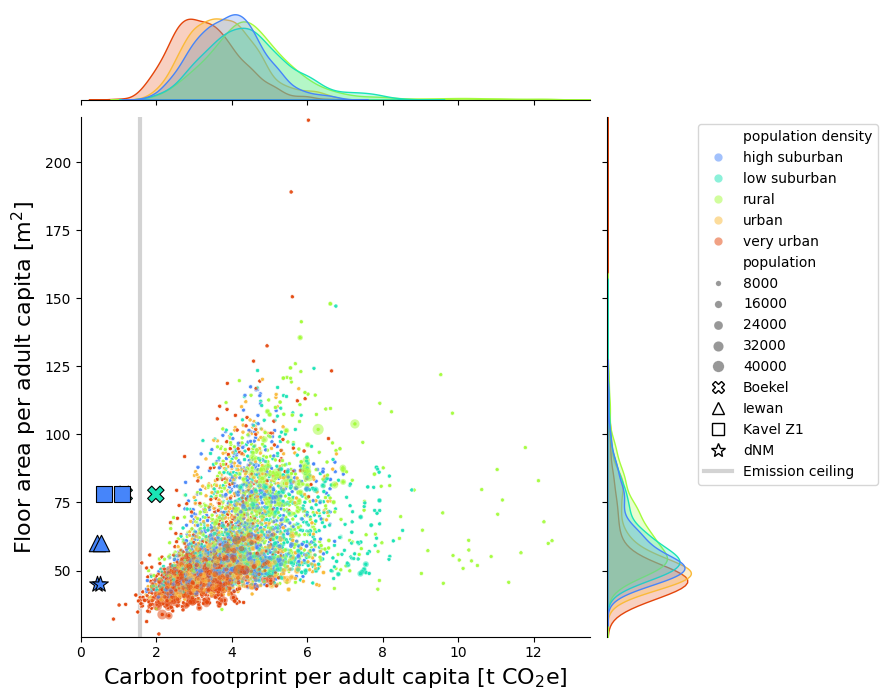

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- BASE FIGURE DATA ---
df = ghg_annual_sum_m2_cap.reset_index()
df.rename(columns={'density_lab': 'population density'}, inplace=True)

# Lock hue mapping so Boekel & Iewan overlays use identical colors
hue_order = sorted(df['population density'].dropna().unique().tolist())
palette_list = sns.color_palette("turbo", n_colors=len(hue_order))
palette = dict(zip(hue_order, palette_list))

# --- JOINTPLOT BASE ---
g = sns.jointplot(
    y="size" + year + "_w1", x="t_co2e",
    hue='population density', data=df,
    hue_order=hue_order, palette=palette,
    marker='.', fc='none', legend=False,
    xlim=(0, ghg_annual_sum_m2_cap["t_co2e"].max() + 1),
    ylim=(ghg_annual_sum_m2_cap["size" + year + "_w1"].min() - 1,
          ghg_annual_sum_m2_cap["size" + year + "_w1"].max() + 1),
    color="0.3", height=7,
)

# Scatter on joint axes with point size ~ population
sns.scatterplot(
    y="size" + year + "_w1", x="t_co2e", data=df,
    hue='population density', hue_order=hue_order, palette=palette,
    size='population', sizes=(2, df['population'].max() / df['population'].min() / 40),
    alpha=0.5, ax=g.ax_joint
)

# --- ADD BOEKEL POINTS (deciles 1–4 only) ---
df_bkl = ghg_annual_sum_m2_cap_boekel.reset_index().copy()
df_bkl = df_bkl[df_bkl['inc_lab'].isin(
    ["decile 1 (poorest)", "decile 2", "decile 3", "decile 4"]
)]
df_bkl.rename(columns={'density_lab': 'population density'}, inplace=True)

# If population is missing in the Boekel df, fill from boekel_df
if 'population' not in df_bkl.columns or df_bkl['population'].isna().any():
    pop_bkl = (
        boekel_df.get(f"n_hhdmem{year}", boekel_df['n_hhdmem'])
                .reindex(ghg_annual_sum_m2_cap_boekel.index)
    )
    df_bkl['population'] = pop_bkl.values

sns.scatterplot(
    y="size" + year + "_w1", x="t_co2e", data=df_bkl,
    hue='population density', hue_order=hue_order, palette=palette,
    marker='X', s=140, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD IEWAN POINTS (deciles 1–4 only) ---
df_iew = ghg_annual_sum_m2_cap_iewan.reset_index().copy()
df_iew = df_iew[df_iew['inc_lab'].isin(
    ["decile 1 (poorest)", "decile 2", "decile 3", "decile 4"]
)]
df_iew.rename(columns={'density_lab': 'population density'}, inplace=True)

# If population is missing in the Iewan df, fill from iewan_df
if 'population' not in df_iew.columns or df_iew['population'].isna().any():
    pop_iew = (
        iewan_df.get(f"n_hhdmem{year}", iewan_df['n_hhdmem'])
                .reindex(ghg_annual_sum_m2_cap_iewan.index)
    )
    df_iew['population'] = pop_iew.values

# Use the color of "high suburban" (fallback to black if not present)
high_suburban_color = palette.get('high suburban', 'black')

# Iewan plotted as triangle with "high suburban" color
sns.scatterplot(
    y="size" + year + "_w1", x="t_co2e", data=df_iew,
    marker='^', s=140, linewidth=0.8,
    edgecolor='black', color=high_suburban_color,
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD Kavel_Z1 POINTS (deciles 2-3 only) ---
df_kavel = ghg_annual_sum_m2_cap_kavel_z1.reset_index().copy()
df_kavel = df_kavel[df_kavel['inc_lab'].isin(
    ["decile 2", "decile 3"]
)]
df_kavel.rename(columns={'density_lab': 'population density'}, inplace=True)

# If population is missing in the Kavel df, fill from kavel_df
if 'population' not in df_kavel.columns or df_kavel['population'].isna().any():
    pop_kavel = (
        kavel_z1_df.get(f"n_hhdmem{year}", kavel_z1_df['n_hhdmem'])
                .reindex(ghg_annual_sum_m2_cap_kavel_z1.index)
    )
    df_kavel['population'] = pop_kavel.values

# Use the color of "high suburban" (fallback to black if not present)
high_suburban_color = palette.get('high suburban', 'black')

# Kavel Z1 plotted as square with "high suburban" color
sns.scatterplot(
    y="size" + year + "_w1", x="t_co2e", data=df_kavel,
    marker='s', s=140, linewidth=0.8,
    edgecolor='black', color=high_suburban_color,
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD dNM POINTS (deciles 2-3 only) ---
df_dnm = ghg_annual_sum_m2_cap_dnm.reset_index().copy()
df_dnm = df_dnm[df_dnm['inc_lab'].isin(
    ["decile 2", "decile 3"]
)]
df_dnm.rename(columns={'density_lab': 'population density'}, inplace=True)

# If population is missing in the dNM df, fill from dnm_df
if 'population' not in df_dnm.columns or df_dnm['population'].isna().any():
    pop_dnm = (
        dnm_df.get(f"n_hhdmem{year}", dnm_df['n_hhdmem'])
                .reindex(ghg_annual_sum_m2_cap_dnm.index)
    )
    df_dnm['population'] = pop_dnm.values

# Use the color of "high suburban" (fallback to black if not present)
high_suburban_color = palette.get('high suburban', 'black')

# dNM plotted as star with "high suburban" color
sns.scatterplot(
    y="size" + year + "_w1", x="t_co2e", data=df_dnm,
    marker='*', s=140, linewidth=0.8,
    edgecolor='black', color=high_suburban_color,
    alpha=1.0, ax=g.ax_joint, legend=False,
    zorder=10
)

# --- ADD EMISSION CEILING LINE (behind points) ---
g.ax_joint.axvline(
    x=1.56,
    color='lightgrey',
    linewidth=3,
    linestyle='-',
    zorder=0  # behind scatter points
)

# Legend handle for emission ceiling
emission_handle = Line2D(
    [], [], color='lightgrey', linestyle='-', linewidth=3,
    label='Emission ceiling'
)

# Legend handle for Boekel (X, colorless)
boekel_handle = Line2D(
    [], [], marker='X', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Boekel'
)

# Legend handle for Iewan (triangle, colorless like Boekel)
iewan_handle = Line2D(
    [], [], marker='^', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Iewan'
)

# Legend handle for Kavel Z1 (square, colorless like Boekel)
kavel_handle = Line2D(
    [], [], marker='s', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Kavel Z1'
)

# Legend handle for dNM (star, colorless like Boekel)
dnm_handle = Line2D(
    [], [], marker='*', linestyle='None',
    markersize=10, markeredgecolor='black',
    markerfacecolor='none', label='dNM'
)

# --- LABELS & LEGENDS ---
g.set_axis_labels(
    'Carbon footprint per adult capita [t CO$_2$e]',
    'Floor area per adult capita [m$^2$]',
    fontsize=16
)

sns.move_legend(g.ax_joint, "upper left", bbox_to_anchor=(1.2, 1))

# Combine legend handles
handles, labels = g.ax_joint.get_legend_handles_labels()
g.ax_joint.legend(
    handles=[*handles, boekel_handle, iewan_handle, kavel_handle, dnm_handle, emission_handle],
    labels=[*labels, 'Boekel', 'Iewan', 'Kavel Z1', 'dNM', 'Emission ceiling'],
    loc='upper left', bbox_to_anchor=(1.2, 1)
)

# --- SAVE ---
outpath = (
    'visualisations/' + class_name_short +
    '/scatter_ghg_m2_urb' + year + age_group + inc_grouping + '.png'
)
g.savefig(outpath, bbox_inches='tight')
print(f"Saved figure to: {outpath}")





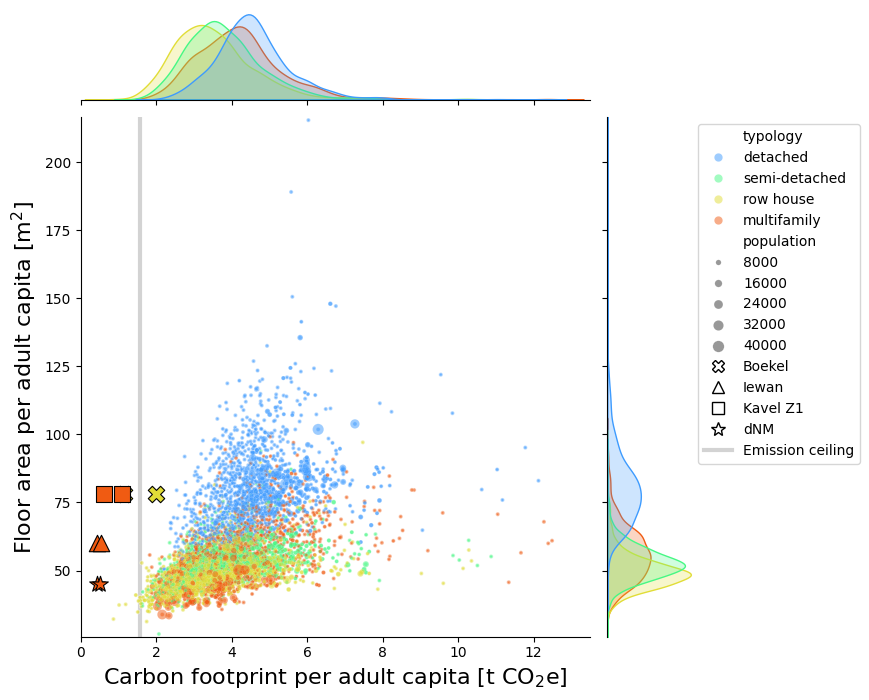

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- BASE DATA ---
df = ghg_annual_sum_m2_cap.reset_index()
df.rename(columns={'typology_lab': 'typology'}, inplace=True)

# --- CONSISTENT HUE ORDER & PALETTE ---
hue_order = ['detached', 'semi-detached', 'row house', 'multifamily']
palette = dict(zip(hue_order, sns.color_palette('turbo', n_colors=len(hue_order))))

df['typology'] = pd.Categorical(df['typology'], categories=hue_order, ordered=True)

# --- BASE JOINTPLOT ---
g = sns.jointplot(
    y=f"size{year}_w1", x="t_co2e", data=df, hue='typology',
    hue_order=hue_order, palette=palette,
    marker='.', fc='none', joint_kws={"alpha": 0.5},
    legend=False, color="0.3", height=7,
    xlim=(0, ghg_annual_sum_m2_cap["t_co2e"].max() + 1),
    ylim=(ghg_annual_sum_m2_cap[f"size{year}_w1"].min() - 1,
          ghg_annual_sum_m2_cap[f"size{year}_w1"].max() + 1),
)

sns.scatterplot(
    y=f"size{year}_w1", x="t_co2e", data=df,
    hue='typology', hue_order=hue_order, palette=palette,
    size='population', sizes=(2, df['population'].max()/df['population'].min()/40),
    alpha=0.5, ax=g.ax_joint
)

# --- ADD BOEKEL POINTS ---
df_bkl = ghg_annual_sum_m2_cap_boekel.reset_index()
df_bkl.rename(columns={'typology_lab': 'typology'}, inplace=True)
df_bkl = df_bkl[df_bkl['inc_lab'].isin([
    "decile 1 (poorest)", "decile 2", "decile 3", "decile 4"
])]
df_bkl['typology'] = 'row house'  # Force color match

# Get color for 'row house'
row_house_color = palette.get('row house', 'black')

sns.scatterplot(
    y=f"size{year}_w1", x="t_co2e", data=df_bkl,
    color=row_house_color,  # fixed to row house color
    marker='X', s=140, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD IEWAN POINTS ---
df_iew = ghg_annual_sum_m2_cap_iewan.reset_index()
df_iew.rename(columns={'typology_lab': 'typology'}, inplace=True)
df_iew = df_iew[df_iew['inc_lab'].isin([
    "decile 1 (poorest)", "decile 2", "decile 3"
])]
df_iew['typology'] = 'multifamily'  # Force color match

# Get color for 'multifamily'
multifamily_color = palette.get('multifamily', 'black')

sns.scatterplot(
    y=f"size{year}_w1", x="t_co2e", data=df_iew,
    color=multifamily_color,  # fixed to multifamily color
    marker='^', s=140, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD KAVEL Z1 POINTS ---
df_kavel = ghg_annual_sum_m2_cap_kavel_z1.reset_index()
df_kavel.rename(columns={'typology_lab': 'typology'}, inplace=True)
df_kavel = df_kavel[df_kavel['inc_lab'].isin([
    "decile 2", "decile 3"
])]
df_kavel['typology'] = 'multifamily'  # Force color match

# Get color for 'multifamily'
multifamily_color = palette.get('multifamily', 'black')

sns.scatterplot(
    y=f"size{year}_w1", x="t_co2e", data=df_kavel,
    color=multifamily_color,  # fixed to multifamily color
    marker='s', s=140, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- ADD dNM POINTS ---
df_dnm = ghg_annual_sum_m2_cap_dnm.reset_index()
df_dnm.rename(columns={'typology_lab': 'typology'}, inplace=True)
df_dnm = df_dnm[df_dnm['inc_lab'].isin([
    "decile 2", "decile 3"
])]
df_dnm['typology'] = 'multifamily'  # Force color match

# Get color for 'multifamily'
multifamily_color = palette.get('multifamily', 'black')

sns.scatterplot(
    y=f"size{year}_w1", x="t_co2e", data=df_dnm,
    color=multifamily_color,  # fixed to multifamily color
    marker='*', s=140, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False
)

# --- EMISSION CEILING LINE (light grey, behind points, with legend) ---
g.ax_joint.axvline(
    x=1.56,
    color='lightgrey',
    linewidth=3,
    linestyle='-',
    zorder=0  # ensure it's behind the scatter points
)

# Legend handles
emission_handle = Line2D([], [], color='lightgrey', linestyle='-', linewidth=3, label='Emission ceiling')

boekel_handle = Line2D(
    [], [], marker='X', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Boekel'
)

iewan_handle = Line2D(
    [], [], marker='^', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Iewan'
)

kavel_handle = Line2D(
    [], [], marker='s', linestyle='None',
    markersize=8, markeredgecolor='black',
    markerfacecolor='none', label='Kavel Z1'
)

dnm_handle = Line2D(
    [], [], marker='*', linestyle='None',
    markersize=10, markeredgecolor='black',
    markerfacecolor='none', label='dNM'
)

# --- LABELS & LEGENDS ---
g.set_axis_labels('Carbon footprint per adult capita [t CO$_2$e]',
                  'Floor area per adult capita [m$^2$]', fontsize=16)

# Move main legend (typology + population) and include extra handles
handles, labels = g.ax_joint.get_legend_handles_labels()
g.ax_joint.legend(
    handles=[*handles, boekel_handle, iewan_handle, kavel_handle, dnm_handle, emission_handle],
    labels=[*labels, 'Boekel', 'Iewan', 'Kavel Z1', 'dNM', 'Emission ceiling'],
    loc='upper left', bbox_to_anchor=(1.2, 1)
)

# --- SAVE ---
g.savefig(f'visualisations/{class_name_short}/scatter_ghg_m2_type{year}{age_group}{inc_grouping}.png')





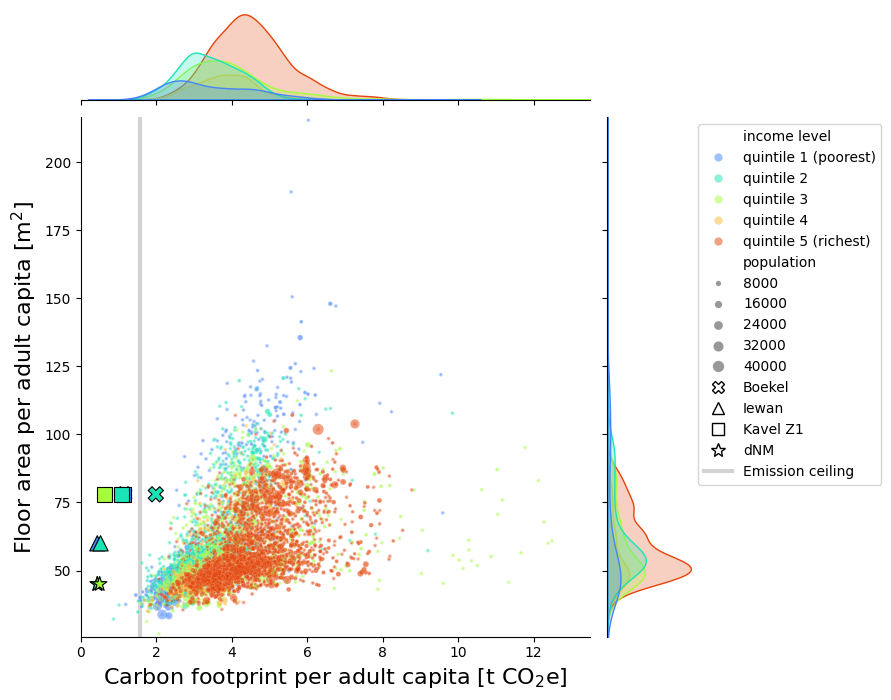

In [ ]:
# Consistent hue order for all plots (QUINTILES)
hue_order = [
    "quintile 1 (poorest)",
    "quintile 2",
    "quintile 3",
    "quintile 4",
    "quintile 5 (richest)",
]

# Build a palette dict keyed by level name
palette_list = sns.color_palette("turbo", n_colors=len(hue_order))
palette = dict(zip(hue_order, palette_list))

# --- MAP DECILES → QUINTILES ---
decile_to_quintile = {
    "decile 1 (poorest)": "quintile 1 (poorest)",
    "decile 2": "quintile 2",
    "decile 3": "quintile 3",
    "decile 4": "quintile 4",
    "decile 5 (richest)": "quintile 5 (richest)",
}

# BASE DATA
df = ghg_annual_sum_m2_cap.reset_index()
df.rename(columns={lab: class_name}, inplace=True)

# Convert income labels from deciles → quintiles
df[class_name] = df[class_name].map(decile_to_quintile)
df[class_name] = pd.Categorical(df[class_name], categories=hue_order, ordered=True)

g = sns.jointplot(
    y="size"+year+"_w1", x="t_co2e", hue=class_name, data=df,
    hue_order=hue_order, palette=palette,
    marker='.', fc='none', legend=False,
    joint_kws={"alpha": 0.3},
    xlim=(0, ghg_annual_sum_m2_cap["t_co2e"].max()+1),
    ylim=(ghg_annual_sum_m2_cap["size"+year+"_w1"].min()-1,
          ghg_annual_sum_m2_cap["size"+year+"_w1"].max()+1),
    color="0.3", height=7,
)

sns.scatterplot(
    y="size"+year+"_w1", x="t_co2e", data=df,
    hue=class_name, hue_order=hue_order, palette=palette,
    size='population', sizes=(2, df['population'].max()/df['population'].min()/40),
    alpha=0.5, ax=g.ax_joint,
)

# --- BOEKEL (convert to quintiles) ---
df_bkl = ghg_annual_sum_m2_cap_boekel.reset_index()
df_bkl.rename(columns={lab: class_name}, inplace=True)
df_bkl[class_name] = df_bkl[class_name].map(decile_to_quintile)
df_bkl = df_bkl[df_bkl[class_name].isin(hue_order[:4])]
df_bkl[class_name] = pd.Categorical(df_bkl[class_name], categories=hue_order, ordered=True)

sns.scatterplot(
    y="size"+year+"_w1", x="t_co2e", data=df_bkl,
    hue=class_name, hue_order=hue_order, palette=palette,
    marker='X', s=120, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False,
)

# --- IEWAN (convert to quintiles) ---
df_iew = ghg_annual_sum_m2_cap_iewan.reset_index()
df_iew.rename(columns={lab: class_name}, inplace=True)
df_iew[class_name] = df_iew[class_name].map(decile_to_quintile)
df_iew = df_iew[df_iew[class_name].isin(hue_order[:3])]
df_iew[class_name] = pd.Categorical(df_iew[class_name], categories=hue_order, ordered=True)

sns.scatterplot(
    y="size"+year+"_w1", x="t_co2e", data=df_iew,
    hue=class_name, hue_order=hue_order, palette=palette,
    marker='^', s=120, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False,
)

# --- KAVEL Z1 (convert to quintiles) ---
df_kavel = ghg_annual_sum_m2_cap_kavel_z1.reset_index()
df_kavel.rename(columns={lab: class_name}, inplace=True)
df_kavel[class_name] = df_kavel[class_name].map(decile_to_quintile)
df_kavel = df_kavel[df_kavel[class_name].isin(hue_order[:3])]
df_kavel[class_name] = pd.Categorical(df_kavel[class_name], categories=hue_order, ordered=True)

sns.scatterplot(
    y="size"+year+"_w1", x="t_co2e", data=df_kavel,
    hue=class_name, hue_order=hue_order, palette=palette,
    marker='s', s=120, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False,
)

# --- dNM (convert to quintiles) ---
df_dnm = ghg_annual_sum_m2_cap_dnm.reset_index()
df_dnm.rename(columns={lab: class_name}, inplace=True)
df_dnm[class_name] = df_dnm[class_name].map(decile_to_quintile)
df_dnm = df_dnm[df_dnm[class_name].isin(hue_order[:3])]
df_dnm[class_name] = pd.Categorical(df_dnm[class_name], categories=hue_order, ordered=True)

sns.scatterplot(
    y="size"+year+"_w1", x="t_co2e", data=df_dnm,
    hue=class_name, hue_order=hue_order, palette=palette,
    marker='*', s=120, linewidth=0.8, edgecolor='black',
    alpha=1.0, ax=g.ax_joint, legend=False,
)

# --- EMISSION CEILING LINE ---
from matplotlib.lines import Line2D

g.ax_joint.axvline(
    x=1.56,
    color='lightgrey',
    linewidth=3,
    linestyle='-',
    zorder=0
)

# Legend handle for emission ceiling
emission_handle = Line2D([], [], color='lightgrey', linestyle='-', linewidth=3, label='Emission ceiling')

# Legend handle for Boekel
boekel_handle = Line2D([], [], marker='X', linestyle='None',
                       markersize=8, markeredgecolor='black',
                       markerfacecolor='none', label='Boekel')

# Legend handle for Iewan
iewan_handle = Line2D([], [], marker='^', linestyle='None',
                      markersize=8, markeredgecolor='black',
                      markerfacecolor='none', label='Iewan')

# Legend handle for Kavel Z1
kavel_handle = Line2D([], [], marker='s', linestyle='None',
                      markersize=8, markeredgecolor='black',
                      markerfacecolor='none', label='Kavel Z1')

# Legend handle for dNM
dnm_handle = Line2D([], [], marker='*', linestyle='None',
                    markersize=10, markeredgecolor='black',
                    markerfacecolor='none', label='dNM')

# Combine legends
handles, labels = g.ax_joint.get_legend_handles_labels()
g.ax_joint.legend(handles=[*handles, boekel_handle, iewan_handle, kavel_handle, dnm_handle, emission_handle],
                  labels=[*labels, 'Boekel', 'Iewan', 'Kavel Z1', 'dNM', 'Emission ceiling'],
                  loc='upper left', bbox_to_anchor=(1.2, 1))

# --- LABELS & SAVE ---
g.set_axis_labels('Carbon footprint per adult capita [t CO$_2$e]',
                  'Floor area per adult capita [m$^2$]', fontsize=16)
sns.move_legend(g.ax_joint, "upper left", bbox_to_anchor=(1.2, 1))

g.savefig('visualisations/'+class_name_short+'/scatter_ghg_m2_class'+year+age_group+inc_grouping+'.png')




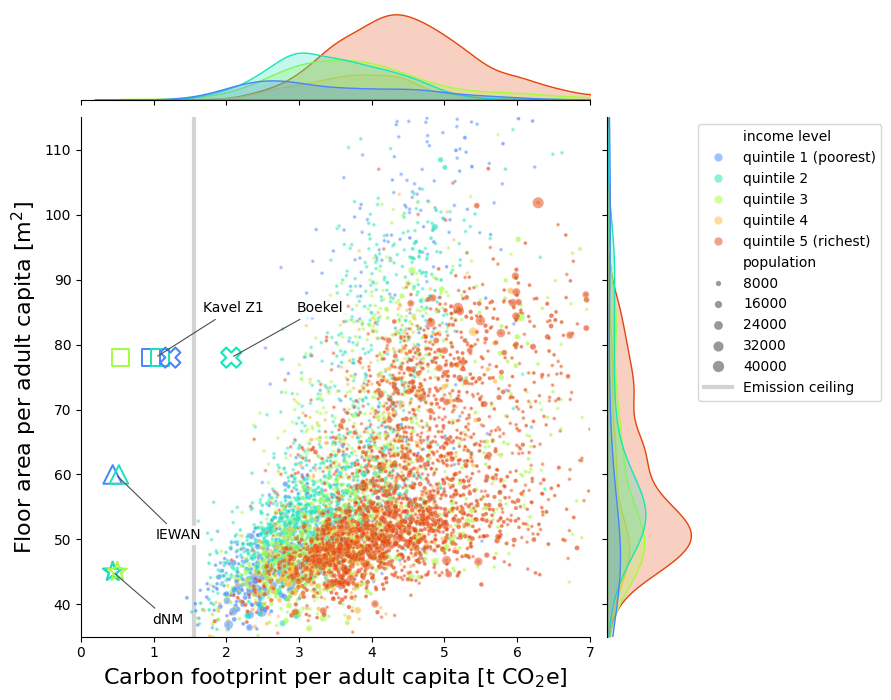

In [ ]:
# Consistent hue order for all plots (QUINTILES)
hue_order = [
    "quintile 1 (poorest)",
    "quintile 2",
    "quintile 3",
    "quintile 4",
    "quintile 5 (richest)",
]

# Build a palette dict keyed by level name
palette_list = sns.color_palette("turbo", n_colors=len(hue_order))
palette = dict(zip(hue_order, palette_list))


# MAP QUINTILES
decile_to_quintile = {
    "decile 1 (poorest)": "quintile 1 (poorest)",
    "decile 2": "quintile 2",
    "decile 3": "quintile 3",
    "decile 4": "quintile 4",
    "decile 5 (richest)": "quintile 5 (richest)",
}


# BASE DATA
df = ghg_annual_sum_m2_cap.reset_index()
df.rename(columns={lab: class_name}, inplace=True)

# Convert income labels from deciles → quintiles
df[class_name] = df[class_name].map(decile_to_quintile)

df[class_name] = pd.Categorical(
    df[class_name],
    categories=hue_order,
    ordered=True
)


# MAIN JOINT PLOT
g = sns.jointplot(
    y="size"+year+"_w1",
    x="t_co2e",
    hue=class_name,
    data=df,
    hue_order=hue_order,
    palette=palette,
    marker=".",
    fc="none",
    legend=False,
    joint_kws={"alpha": 0.3},
    xlim=(0, 7),
    ylim=(35, 115),
    color="0.3",
    height=7,
)


# Base population scatter
sns.scatterplot(
    y="size"+year+"_w1",
    x="t_co2e",
    data=df,
    hue=class_name,
    hue_order=hue_order,
    palette=palette,
    size="population",
    sizes=(
        2,
        df["population"].max() / df["population"].min() / 40
    ),
    alpha=0.5,
    ax=g.ax_joint,
)


# Display-only offsets between archetypes
archetype_offsets = {
    "Boekel": (0.08, 0.0),
    "IEWAN": (0.0, 0.0),
    "Kavel Z1": (-0.08, 0.0),
    "dNM": (0.0, 0.0),
}


# HELPER FUNCTION FOR HOLLOW ARCHETYPE MARKERS
def plot_hollow_archetype(
    ax,
    data,
    marker,
    archetype_name,
    size=150,
    linewidth=1.4,
    zorder=15
):

    x_offset, y_offset = archetype_offsets[archetype_name]

    for q in hue_order:

        temp = data[data[class_name] == q]

        if len(temp) == 0:
            continue

        ax.scatter(
            temp["t_co2e"] + x_offset,
            temp["size"+year+"_w1"] + y_offset,
            marker=marker,
            s=size,
            facecolors="none",
            edgecolors=[palette[q]],
            linewidths=linewidth,
            alpha=1.0,
            zorder=zorder
        )


# BOEKEL
df_bkl = ghg_annual_sum_m2_cap_boekel.reset_index()
df_bkl.rename(columns={lab: class_name}, inplace=True)

df_bkl[class_name] = df_bkl[class_name].map(decile_to_quintile)

df_bkl = df_bkl[
    df_bkl[class_name].isin(hue_order[:4])
]

df_bkl[class_name] = pd.Categorical(
    df_bkl[class_name],
    categories=hue_order,
    ordered=True
)

plot_hollow_archetype(
    ax=g.ax_joint,
    data=df_bkl,
    marker="X",
    archetype_name="Boekel",
    size=210,
    linewidth=1.5,
    zorder=18
)


# IEWAN
df_iew = ghg_annual_sum_m2_cap_iewan.reset_index()
df_iew.rename(columns={lab: class_name}, inplace=True)

df_iew[class_name] = df_iew[class_name].map(decile_to_quintile)

df_iew = df_iew[
    df_iew[class_name].isin(hue_order[:3])
]

df_iew[class_name] = pd.Categorical(
    df_iew[class_name],
    categories=hue_order,
    ordered=True
)

plot_hollow_archetype(
    ax=g.ax_joint,
    data=df_iew,
    marker="^",
    archetype_name="IEWAN",
    size=180,
    linewidth=1.4,
    zorder=16
)


# KAVEL Z1
df_kavel = ghg_annual_sum_m2_cap_kavel_z1.reset_index()
df_kavel.rename(columns={lab: class_name}, inplace=True)

df_kavel[class_name] = df_kavel[class_name].map(decile_to_quintile)

df_kavel = df_kavel[
    df_kavel[class_name].isin(hue_order[:3])
]

df_kavel[class_name] = pd.Categorical(
    df_kavel[class_name],
    categories=hue_order,
    ordered=True
)


# Plot Kavel Z1 squares individually
# This allows the first two squares to be separated visually
kavel_base_x_offset = archetype_offsets["Kavel Z1"][0]
kavel_base_y_offset = archetype_offsets["Kavel Z1"][1]

# One square moves left and the other moves right
kavel_separation = 0.08

for i, (_, row) in enumerate(df_kavel.iterrows()):

    if i == 0:
        individual_x_offset = -kavel_separation

    elif i == 1:
        individual_x_offset = kavel_separation

    else:
        individual_x_offset = 0.0

    g.ax_joint.scatter(
        row["t_co2e"]
        + kavel_base_x_offset
        + individual_x_offset,

        row["size"+year+"_w1"]
        + kavel_base_y_offset,

        marker="s",
        s=160,
        facecolors="none",
        edgecolors=[palette[row[class_name]]],
        linewidths=1.4,
        alpha=1.0,
        zorder=17
    )


# dNM
df_dnm = ghg_annual_sum_m2_cap_dnm.reset_index()
df_dnm.rename(columns={lab: class_name}, inplace=True)

df_dnm[class_name] = df_dnm[class_name].map(decile_to_quintile)

df_dnm = df_dnm[
    df_dnm[class_name].isin(hue_order[:3])
]

df_dnm[class_name] = pd.Categorical(
    df_dnm[class_name],
    categories=hue_order,
    ordered=True
)

plot_hollow_archetype(
    ax=g.ax_joint,
    data=df_dnm,
    marker="*",
    archetype_name="dNM",
    size=210,
    linewidth=1.4,
    zorder=16
)


# EMISSION CEILING
from matplotlib.lines import Line2D

g.ax_joint.axvline(
    x=1.56,
    color="lightgrey",
    linewidth=3,
    linestyle="-",
    zorder=0
)

emission_handle = Line2D(
    [], [],
    color="lightgrey",
    linestyle="-",
    linewidth=3,
    label="Emission ceiling"
)


# ARCHETYPE CALLOUT POSITIONS

# Boekel: select an actual Boekel point close to the middle
boekel_mid_x = df_bkl["t_co2e"].median()

boekel_point = df_bkl.loc[
    (df_bkl["t_co2e"] - boekel_mid_x).abs().idxmin()
]

boekel_x = (
    boekel_point["t_co2e"]
    + archetype_offsets["Boekel"][0]
)

boekel_y = (
    boekel_point["size"+year+"_w1"]
    + archetype_offsets["Boekel"][1]
)


# IEWAN
iewan_x = (
    df_iew["t_co2e"].median()
    + archetype_offsets["IEWAN"][0]
)

iewan_y = (
    df_iew["size"+year+"_w1"].median()
    + archetype_offsets["IEWAN"][1]
)


# Kavel Z1
# Callout points to the centre between the two separated squares
if len(df_kavel) >= 2:

    kavel_x = (
        df_kavel.iloc[:2]["t_co2e"].mean()
        + kavel_base_x_offset
    )

    kavel_y = (
        df_kavel.iloc[:2]["size"+year+"_w1"].mean()
        + kavel_base_y_offset
    )

else:

    kavel_x = (
        df_kavel["t_co2e"].median()
        + kavel_base_x_offset
    )

    kavel_y = (
        df_kavel["size"+year+"_w1"].median()
        + kavel_base_y_offset
    )


# dNM
dnm_x = (
    df_dnm["t_co2e"].median()
    + archetype_offsets["dNM"][0]
)

dnm_y = (
    df_dnm["size"+year+"_w1"].median()
    + archetype_offsets["dNM"][1]
)


# Boekel callout
g.ax_joint.annotate(
    "Boekel",
    xy=(boekel_x, boekel_y),
    xytext=(boekel_x + 0.90, boekel_y + 7),
    fontsize=10,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=0.8,
        color="0.3"
    ),
    bbox=dict(
        boxstyle="round,pad=0.2",
        fc="white",
        ec="none",
        alpha=0.85
    ),
    zorder=20
)


# IEWAN callout
g.ax_joint.annotate(
    "IEWAN",
    xy=(iewan_x, iewan_y),
    xytext=(iewan_x + 0.55, iewan_y - 10),
    fontsize=10,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=0.8,
        color="0.3"
    ),
    bbox=dict(
        boxstyle="round,pad=0.2",
        fc="white",
        ec="none",
        alpha=0.85
    ),
    zorder=20
)


# Kavel Z1 callout
g.ax_joint.annotate(
    "Kavel Z1",
    xy=(kavel_x, kavel_y),
    xytext=(kavel_x + 0.65, kavel_y + 7),
    fontsize=10,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=0.8,
        color="0.3"
    ),
    bbox=dict(
        boxstyle="round,pad=0.2",
        fc="white",
        ec="none",
        alpha=0.85
    ),
    zorder=20
)


# dNM callout
g.ax_joint.annotate(
    "dNM",
    xy=(dnm_x, dnm_y),
    xytext=(dnm_x + 0.55, dnm_y - 8),
    fontsize=10,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=0.8,
        color="0.3"
    ),
    bbox=dict(
        boxstyle="round,pad=0.2",
        fc="white",
        ec="none",
        alpha=0.85
    ),
    zorder=20
)


# ARCHETYPE LEGEND HANDLES
boekel_handle = Line2D(
    [], [],
    marker="X",
    linestyle="None",
    markersize=9,
    markeredgewidth=0.8,
    markeredgecolor="black",
    markerfacecolor="none",
    label="Boekel"
)

iewan_handle = Line2D(
    [], [],
    marker="^",
    linestyle="None",
    markersize=9,
    markeredgewidth=0.8,
    markeredgecolor="black",
    markerfacecolor="none",
    label="IEWAN"
)

kavel_handle = Line2D(
    [], [],
    marker="s",
    linestyle="None",
    markersize=9,
    markeredgewidth=0.8,
    markeredgecolor="black",
    markerfacecolor="none",
    label="Kavel Z1"
)

dnm_handle = Line2D(
    [], [],
    marker="*",
    linestyle="None",
    markersize=11,
    markeredgewidth=0.8,
    markeredgecolor="black",
    markerfacecolor="none",
    label="dNM"
)


# LEGEND
handles, labels = g.ax_joint.get_legend_handles_labels()

g.ax_joint.legend(
    handles=[
        *handles,
        emission_handle
    ],
    labels=[
        *labels,
        "Emission ceiling"
    ],
    loc="upper left",
    bbox_to_anchor=(1.2, 1)
)


# AXIS LIMITS
g.ax_joint.set_xlim(0, 7)
g.ax_joint.set_ylim(35, 115)

g.ax_marg_x.set_xlim(0, 7)
g.ax_marg_y.set_ylim(35, 115)


# LABELS
g.set_axis_labels(
    "Carbon footprint per adult capita [t CO$_2$e]",
    "Floor area per adult capita [m$^2$]",
    fontsize=16
)

sns.move_legend(
    g.ax_joint,
    "upper left",
    bbox_to_anchor=(1.2, 1)
)


# SAVE
g.savefig(
    "visualisations/"
    + class_name_short
    + "/scatter_ghg_m2_class"
    + year
    + age_group
    + inc_grouping
    + ".png",
    dpi=300,
    bbox_inches="tight"
)

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# ---------- Boekel ----------
ghg_annual_df_boekel = ghg_annual_boekel.copy() / 1000  # convert to t CO2e
ghg_annual_df_boekel.columns = [
    'Building material', 'Heat pump', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

df_boekel = (
    ghg_annual_df_boekel
    .multiply(boekel_df['n_hhd'], axis=0)
    .div(boekel_df['n_hhdmem'], axis=0)
    .groupby(level=0, sort=False)
    .mean()
    .unstack()
    .reset_index()
)
df_boekel.columns = ['process', class_name, 'value']

df_boekel[class_name] = df_boekel[class_name].replace({'decile 2': 'quintile 2'})
df_boekel = df_boekel[df_boekel[class_name] == 'quintile 2']
df_boekel[class_name] = 'Boekel quintile 2'

# ---------- USE / BAU----------
ghg_annual_df_use = ghg_annual.copy() / 1000
ghg_annual_df_use.columns = [
    'Building material', 'Heat pump', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

df_use = (
    ghg_annual_df_use
    .multiply(use['n_hhd'], axis=0)
    .div(use['n_hhdmem' + year], axis=0)
    .groupby(level=0, sort=False)
    .mean()
    .unstack()
    .reset_index()
)
df_use.columns = ['process', class_name, 'value']

df_use[class_name] = df_use[class_name].replace({'decile 2': 'quintile 2'})
df_use = df_use[df_use[class_name] == 'quintile 2']
df_use[class_name] = 'BAU quintile 2'

# ---------- Iewan (quintile 3, HAS FURNACE PELLET EXTRA) ----------
ghg_annual_df_iewan = ghg_annual_iewan.copy() / 1000
ghg_annual_df_iewan.columns = [
    'Building material', 'Heat pump', 'Furnace pellet' ,'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

df_iewan = (
    ghg_annual_df_iewan
    .multiply(iewan_df['n_hhd'], axis=0)
    .div(iewan_df['n_hhdmem'], axis=0)
    .groupby(level=0, sort=False)
    .mean()
    .unstack()
    .reset_index()
)
df_iewan.columns = ['process', class_name, 'value']

df_iewan[class_name] = df_iewan[class_name].replace({'decile 2': 'quintile 2'})
df_iewan = df_iewan[df_iewan[class_name] == 'quintile 2']
df_iewan[class_name] = 'Iewan quintile 2'

# ---------- Kavel Z1 (quintile 3) ----------
ghg_annual_df_kavel_z1 = ghg_annual_kavel_z1.copy() / 1000
ghg_annual_df_kavel_z1.columns = [
    'Building material', 'Heat pump', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

df_kavel = (
    ghg_annual_df_kavel_z1
    .multiply(kavel_z1_df['n_hhd'], axis=0)
    .div(kavel_z1_df['n_hhdmem'], axis=0)
    .groupby(level=0, sort=False)
    .mean()
    .unstack()
    .reset_index()
)
df_kavel.columns = ['process', class_name, 'value']

df_kavel[class_name] = df_kavel[class_name].replace({'decile 2': 'quintile 2'})
df_kavel = df_kavel[df_kavel[class_name] == 'quintile 2']
df_kavel[class_name] = 'Kavel Z1 quintile 2'

# ---------- dNM (quintile 3) ----------
ghg_annual_df_dnm = ghg_annual_dnm.copy() / 1000
ghg_annual_df_dnm.columns = [
    'Building material', 'Heat pump', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

df_dnm = (
    ghg_annual_df_dnm
    .multiply(dnm_df['n_hhd'], axis=0)
    .div(dnm_df['n_hhdmem'], axis=0)
    .groupby(level=0, sort=False)
    .mean()
    .unstack()
    .reset_index()
)
df_dnm.columns = ['process', class_name, 'value']

df_dnm[class_name] = df_dnm[class_name].replace({'decile 2': 'quintile 2'})
df_dnm = df_dnm[df_dnm[class_name] == 'quintile 2']
df_dnm[class_name] = 'dNM quintile 2'

# ---------- Combine ----------
df_compare = pd.concat([df_boekel, df_use, df_iewan, df_kavel, df_dnm], ignore_index=True)

# ---------- Create figure ----------
fig = px.bar(
    df_compare,
    x='value',
    y=class_name,
    color='process',
    labels={'value': 'Carbon footprint of housing per adult capita per year [t CO<sub>2</sub>e]'},
    template='simple_white',
    color_discrete_sequence=[
        'rgb(000,000,000)',  # Building material
        'rgb(204,121,167)',  # Heat pump
        'rgb(126,041,084)',  # District heating
        'rgb(213,094,000)',  # Gas
        'rgb(230,159,000)',  # Electricity
        'rgb(240,228,066)',  # PV
        'rgb(000,114,178)',  # Car use
        'rgb(086,180,233)',  # Transit
        'rgb(000,158,115)',  # Cycling
        'rgb(139,069,019)'   # Furnace pellet
    ]
)

# ---------- Add emission ceiling ----------
fig.add_vline(x=1.64, line_width=3, line_color="grey")

fig.add_trace(
    go.Scatter(x=[None], y=[None],
               mode='lines',
               line=dict(color='grey', width=3),
               name='Emission ceiling')
)

# ---------- Layout ----------
fig.update_layout(
    width=1000,
    height=300 + len(df_compare[class_name].unique()) * 100,
    font=dict(size=18),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    )
)

fig.update_traces(marker_line_width=0)

# ---------- Axis ----------
fig.update_xaxes(range=[0, 4])
fig.update_yaxes(categoryorder='array',
                 categoryarray=['BAU quintile 3', 'Boekel quintile 3', 'Iewan quintile 3', 'Kavel Z1 quintile 3', 'dNM quintile 3'])

# ---------- Save ----------
fig.write_image(
    'visualisations/' + class_name_short +
    '/stackedbars_ghg_per_cap_process_' +
    class_name_short + year + age_group + inc_grouping +
    '_quintile3compare.png',
    scale=3
)

fig.write_image('visualisations/'+class_name_short+'/stackedbars_ghg_per_cap_process_'+class_name_short+year+age_group+inc_grouping+'.png', scale=3)
fig.show()





In [ ]:
#for entire population
df = ghg_annual.multiply(use['n_hhd'], axis=0).groupby(level=0, sort=False).sum().unstack().reset_index()
df.columns = ['process', class_name, 'value']

fig = px.bar(df, x='value', y=class_name,color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per year [kg CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
fig.update_traces(marker_line_width=0)

#### Tenure Bar

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# ---------- Process columns ----------
process_cols_9 = [
    'Building material', 'Heat pump', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]

process_cols_10 = [
    'Building material', 'Heat pump', 'Furnace pellet', 'District heating',
    'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling'
]


# ---------- Helper function for real-utopian archetypes ----------
def make_long_df(ghg_df, base_df, label, process_cols):
    ghg_tmp = ghg_df.copy() / 1000
    ghg_tmp.columns = process_cols

    per_capita = (
        ghg_tmp
        .multiply(base_df['n_hhd'], axis=0)
        .div(base_df['n_hhdmem'], axis=0)
    )

    # Average each emissions component across all archetype rows.
    df = per_capita.mean(axis=0).rename('value').reset_index()
    df.columns = ['process', 'value']
    df[class_name] = label

    return df


# ---------- Helper function for archetype-specific USE / Default ----------
def make_use_archetype_df(label, tenure, typology, const, density, distance_train):
    ghg_tmp = ghg_annual.copy() / 1000
    ghg_tmp.columns = process_cols_9

    use_filter = (
        (use.index.get_level_values('tenure_lab') == tenure) &
        (use.index.get_level_values('typology_lab') == typology) &
        (use.index.get_level_values('const_lab') == const) &
        (use.index.get_level_values('density_lab') == density) &
        (use.index.get_level_values('distance_train_lab') == distance_train)
    )

    df = (
        ghg_tmp.loc[use_filter]
        .multiply(use.loc[use_filter, 'n_hhd'], axis=0)
        .div(use.loc[use_filter, 'n_hhdmem' + year], axis=0)
        .groupby(level=0, sort=False)
        .mean()
        .unstack()
        .reset_index()
    )

    df.columns = ['process', class_name, 'value']
    df[class_name] = label

    return df


# ---------- Boekel + matching Default ----------
df_boekel = make_long_df(
    ghg_annual_boekel,
    boekel_df,
    'Boekel',
    process_cols_9,
)

df_use_boekel = make_use_archetype_df(
    label='Default - Boekel match',
    tenure='owner occupied',
    typology='row house',
    const='2006-2022',
    density='low suburban',
    distance_train='furthest quintile'
)


# ---------- Iewan + matching Default ----------
df_iewan = make_long_df(
    ghg_annual_iewan,
    iewan_df,
    'Iewan',
    process_cols_10,
)

df_use_iewan = make_use_archetype_df(
    label='Default - Iewan match',
    tenure='social rental',
    typology='multifamily',
    const='2006-2022',
    density='high suburban',
    distance_train='2nd quintile'
)


# ---------- Kavel Z1 + matching Default ----------
df_kavel = make_long_df(
    ghg_annual_kavel_z1,
    kavel_z1_df,
    'Kavel Z1',
    process_cols_9,
)

df_use_kavel = make_use_archetype_df(
    label='Default - Kavel Z1 match',
    tenure='social rental',
    typology='multifamily',
    const='2006-2022',
    density='very urban',
    distance_train='nearest quintile'
)


# ---------- dNM + matching Default ----------
df_dnm = make_long_df(
    ghg_annual_dnm,
    dnm_df,
    'dNM',
    process_cols_9,
)

df_use_dnm = make_use_archetype_df(
    label='Default - dNM match',
    tenure='owner occupied',
    typology='multifamily',
    const='2006-2022',
    density='very urban',
    distance_train='nearest quintile'
)


# ---------- Combine ----------
df_compare = pd.concat([
    df_boekel.assign(y_order='Boekel__prototype', y_label='Boekel'),
    df_use_boekel.assign(y_order='Boekel__default', y_label='Default'),

    df_iewan.assign(y_order='Iewan__prototype', y_label='Iewan'),
    df_use_iewan.assign(y_order='Iewan__default', y_label='Default'),

    df_kavel.assign(y_order='Kavel Z1__prototype', y_label='Kavel Z1'),
    df_use_kavel.assign(y_order='Kavel Z1__default', y_label='Default'),

    df_dnm.assign(y_order='dNM__prototype', y_label='dNM'),
    df_use_dnm.assign(y_order='dNM__default', y_label='Default')
], ignore_index=True)


# ---------- Create figure ----------
fig = px.bar(
    df_compare,
    x='value',
    y='y_order',
    color='process',
    labels={
        'value': 'Carbon footprint of housing per adult capita per year [t CO<sub>2</sub>e]',
        'y_order': 'Tenure'
    },
    template='simple_white',
    color_discrete_sequence=[
        'rgb(000,000,000)',
        'rgb(204,121,167)',
        'rgb(126,041,084)',
        'rgb(213,094,000)',
        'rgb(230,159,000)',
        'rgb(240,228,066)',
        'rgb(000,114,178)',
        'rgb(086,180,233)',
        'rgb(000,158,115)',
        'rgb(139,069,019)'
    ]
)


# ---------- Add emission ceiling ----------
fig.add_vline(x=1.64, line_width=3, line_color="grey")

fig.add_trace(
    go.Scatter(
        x=[None],
        y=[None],
        mode='lines',
        line=dict(color='grey', width=3),
        name='Emission ceiling'
    )
)


# ---------- Layout ----------
fig.update_layout(
    width=1100,
    height=900,
    font=dict(size=18),

    # small gap within each prototype/default pair
    # larger visual spacing created with y-axis blank categories below
    bargap=0.05,
    bargroupgap=0.0,

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    )
)

fig.update_traces(marker_line_width=0)


# ---------- Axis ----------
fig.update_xaxes(range=[0, 5])

fig.update_yaxes(
    categoryorder='array',
    categoryarray=[
        'dNM__space',
        'dNM__default',
        'dNM__prototype',

        'Kavel Z1__space',
        'Kavel Z1__default',
        'Kavel Z1__prototype',

        'Iewan__space',
        'Iewan__default',
        'Iewan__prototype',

        'Boekel__space',
        'Boekel__default',
        'Boekel__prototype'
    ],
    tickmode='array',
    tickvals=[
        'dNM__prototype',
        'dNM__default',

        'Kavel Z1__prototype',
        'Kavel Z1__default',

        'Iewan__prototype',
        'Iewan__default',

        'Boekel__prototype',
        'Boekel__default'
    ],
    ticktext=[
        'dNM',
        'Default',

        'Kavel Z1',
        'Default',

        'Iewan',
        'Default',

        'Boekel',
        'Default'
    ]
)


# ---------- Save ----------
fig.write_image(
    'visualisations/' + class_name_short +
    '/doublebars_ghg_per_cap_process_' +
    class_name_short + year + age_group + inc_grouping +
    '_archetype_compare.png',
    scale=3
)

fig.show()

## Trash

Multinomial Logistic Regression (housing dynamics forecast)

In [ ]:
import pandas as pd
import numpy as np
import math
import os

years = np.arange(2014, 2027)
data = {
    "appartement":   [0.52, 0.495049505, 0.478564307, 0.485148515, 0.5, 0.524752475, 0.56, 0.596562184, 0.623762376, 0.66, 0.71, 0.72, 0.742],
    "rijtjeshuis":   [0.23, 0.218, 0.232, 0.219, 0.201, 0.183, 0.164, 0.152, 0.134, 0.123, 0.11, 0.105, 0.096],
    "hoekhuis":      [0.09, 0.096, 0.102, 0.097, 0.094, 0.087, 0.081, 0.073, 0.065, 0.059, 0.054, 0.052, 0.048],
    "2 onder 1 kap": [0.08, 0.079207921, 0.089730808, 0.089108911, 0.09, 0.089108911, 0.08, 0.070778564, 0.069306931, 0.06, 0.05, 0.05, 0.044],
    "vrijstaand":    [0.11, 0.108910891, 0.102691924, 0.108910891, 0.12, 0.118811881, 0.12, 0.110212336, 0.108910891, 0.1, 0.08, 0.07, 0.071],
}

df = pd.DataFrame(data, index=years)
df.index.name = "Year"

# Normalize so each year sums to 1
df = df.div(df.sum(axis=1), axis=0)

cats = list(df.columns)
ref = "appartement"
others = [c for c in cats if c != ref]


# Fit multinomial logit trends in log-ratio space
# ln(p_i/p_ref) = intercept_i + slope_i * t
t = (df.index.values - 2014).astype(float)
eps = 1e-12

coefs = {}
for c in others:
    y = np.log((df[c].values + eps) / (df[ref].values + eps))
    slope, intercept = np.polyfit(t, y, 1)
    coefs[c] = (slope, intercept)

# dampening
half_life_years = 12.0  
lam = math.log(2) / half_life_years

last_obs_year = 2026
t_last = last_obs_year - 2014

def t_effective(year: int) -> float:
    """
    Uses normal time up to last_obs_year, then applies damped extra time beyond it:
      eff_delta = (1 - exp(-lam * delta)) / lam
    This saturates as year increases, preventing runaway dominance.
    """
    if year <= last_obs_year:
        return year - 2014
    delta = year - last_obs_year
    eff_delta = (1 - math.exp(-lam * delta)) / lam
    return t_last + eff_delta

# forecast 2026–2050 
future_years = np.arange(2027, 2051)

def softmax_forecast(year: int) -> dict:
    te = t_effective(year)
    logits = {ref: 0.0}
    for c in others:
        m, b = coefs[c]
        logits[c] = m * te + b

    exp_vals = {c: math.exp(v) for c, v in logits.items()}
    total = sum(exp_vals.values())
    return {c: exp_vals[c] / total for c in cats}

df_future = pd.DataFrame([softmax_forecast(y) for y in future_years], index=future_years)
df_future.index.name = "Year"

df_all = pd.concat([df, df_future], axis=0)
df_all["Sum"] = df_all[cats].sum(axis=1)

# save to Excel
output_dir = "data_input"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "housing_types_forecast.xlsx")
df_all.to_excel(output_path)


Scenario Analysis

In [ ]:
# ============================================================
# CURRENT HOUSING COUNTS
# building type × construction period × urbanity
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Use the already-loaded 'use' dataframe
# ------------------------------------------------------------

# 'use' has a MultiIndex:
# [inc_lab, typology_lab, const_lab, density_lab, distance_train_lab]
#
# n_hhd = number of households / dwellings represented by each profile

housing_counts = (
    use['n_hhd']
    .groupby(
        level=[
            'typology_lab',
            'const_lab',
            'density_lab'
        ],
        sort=False
    )
    .sum()
    .rename('n_dwellings')
    .reset_index()
)


# ------------------------------------------------------------
# 2. Sort the output in a useful order
# ------------------------------------------------------------

typology_order = [
    'multifamily',
    'detached',
    'semi-detached',
    'row house'
]

construction_order = [
    'pre 1945',
    '1945-1964',
    '1965-1974',
    '1975-1991',
    '1992-2005',
    '2006-2022'
]

urbanity_order = [
    'very urban',
    'urban',
    'high suburban',
    'low suburban',
    'rural'
]

housing_counts['typology_lab'] = pd.Categorical(
    housing_counts['typology_lab'],
    categories=typology_order,
    ordered=True
)

housing_counts['const_lab'] = pd.Categorical(
    housing_counts['const_lab'],
    categories=construction_order,
    ordered=True
)

housing_counts['density_lab'] = pd.Categorical(
    housing_counts['density_lab'],
    categories=urbanity_order,
    ordered=True
)

housing_counts = housing_counts.sort_values(
    ['typology_lab', 'const_lab', 'density_lab']
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Add shares within each building type × construction period
# ------------------------------------------------------------
# This is especially useful later for allocating ETM demolition
# across urbanity classes.

housing_counts['urbanity_share'] = (
    housing_counts['n_dwellings']
    /
    housing_counts.groupby(
        ['typology_lab', 'const_lab'],
        observed=True
    )['n_dwellings'].transform('sum')
)


# ------------------------------------------------------------
# 4. Print / inspect
# ------------------------------------------------------------

print(housing_counts)

print("\nTotal number of dwellings represented:")
print(housing_counts['n_dwellings'].sum())


# ------------------------------------------------------------
# 5. Optional: pivot table for easier inspection
# ------------------------------------------------------------

housing_counts_pivot = housing_counts.pivot_table(
    index=['typology_lab', 'const_lab'],
    columns='density_lab',
    values='n_dwellings',
    aggfunc='sum',
    fill_value=0,
    observed=True
)

print("\nHousing counts by building type × construction period × urbanity:")
display(housing_counts_pivot)


# ------------------------------------------------------------
# 6. Save to Excel
# ------------------------------------------------------------

output_path = 'data_input/output/current_housing_counts_typology_age_urbanity.xlsx'

with pd.ExcelWriter(output_path) as writer:
    housing_counts.to_excel(
        writer,
        sheet_name='long_format',
        index=False
    )

    housing_counts_pivot.to_excel(
        writer,
        sheet_name='pivot_counts'
    )

print(f"\nSaved to: {output_path}")

In [ ]:
import pandas as pd

# ============================================================
# 1. LOAD ODIN DATA
# ============================================================

file_path = "data_input/output/income density distance privacy odin 2023.xlsx"

odin = pd.read_excel(file_path, sheet_name="Sheet1")


# ============================================================
# 2. AGGREGATE ACROSS INCOME
# ============================================================
# We want mobility profiles defined ONLY by:
#
#   urbanity × distance to train station
#
# Therefore, income is summed over.
#
# We sum total annual passenger-km and number of households
# first, and then calculate mobility per household.

mobility_profiles = (
    odin
    .groupby(
        ["density_lab", "distance_train_lab"],
        observed=True
    )
    .agg(
        n_hhd=("n_hhd", "sum"),

        car_pkm_total=("dist_carpp_py", "sum"),
        transit_pkm_total=("dist_transit_py", "sum"),
        cycle_pkm_total=("dist_cycle_py", "sum"),
        walk_pkm_total=("dist_walk_py", "sum")
    )
    .reset_index()
)


# ============================================================
# 3. CALCULATE ANNUAL MOBILITY PER HOUSEHOLD
# ============================================================

mobility_profiles["car_pkm_hhd"] = (
    mobility_profiles["car_pkm_total"]
    / mobility_profiles["n_hhd"]
)

mobility_profiles["transit_pkm_hhd"] = (
    mobility_profiles["transit_pkm_total"]
    / mobility_profiles["n_hhd"]
)

mobility_profiles["cycle_pkm_hhd"] = (
    mobility_profiles["cycle_pkm_total"]
    / mobility_profiles["n_hhd"]
)

mobility_profiles["walk_pkm_hhd"] = (
    mobility_profiles["walk_pkm_total"]
    / mobility_profiles["n_hhd"]
)


# ============================================================
# 4. KEEP FINAL MOBILITY PROFILE VARIABLES
# ============================================================

mobility_profiles = mobility_profiles[
    [
        "density_lab",
        "distance_train_lab",
        "n_hhd",
        "car_pkm_hhd",
        "transit_pkm_hhd",
        "cycle_pkm_hhd",
        "walk_pkm_hhd"
    ]
].copy()


# Rename columns for clarity
mobility_profiles = mobility_profiles.rename(
    columns={
        "density_lab": "urbanity",
        "distance_train_lab": "distance_station"
    }
)


# ============================================================
# 5. SORT AND DISPLAY
# ============================================================

mobility_profiles = (
    mobility_profiles
    .sort_values(
        ["urbanity", "distance_station"]
    )
    .reset_index(drop=True)
)

display(mobility_profiles)

,urbanity,distance_station,n_hhd,car_pkm_hhd,transit_pkm_hhd,cycle_pkm_hhd,walk_pkm_hhd
0,high suburban,2nd quintile,"205,075.00","16,454.44","4,418.35","2,831.07","1,242.68"
1,high suburban,3nd quintile,"235,345.00","18,643.45","2,551.46","3,267.48","1,139.38"
2,high suburban,4nd quintile,"214,610.00","17,802.56","2,148.13","3,360.59","1,027.58"
3,high suburban,furthest quintile,"244,210.00","15,088.69","2,458.51","2,425.56","1,039.15"
4,high suburban,nearest quintile,"189,220.00","14,718.69","3,871.88","2,673.44","1,160.66"
5,low suburban,2nd quintile,"103,910.00","20,189.28","3,614.71","3,198.81","1,138.19"
6,low suburban,3nd quintile,"140,190.00","18,817.08","5,082.18","3,133.91","1,051.86"
7,low suburban,4nd quintile,"229,385.00","20,542.05","2,920.05","3,562.04","1,134.46"
8,low suburban,furthest quintile,"315,040.00","23,908.52","2,483.89","2,968.44","1,077.34"
9,low suburban,nearest quintile,"118,030.00","18,077.63","3,127.68","2,878.11","1,114.35"


In [ ]:
import pandas as pd

# ============================================================
# HOUSEHOLD COMPOSITION PROFILES
# Building type × Urbanity
# ============================================================

# Reset index so building type and urbanity are columns
df = use.reset_index()


# ============================================================
# 1. AGGREGATE HOUSEHOLD COUNTS AND MEMBERS
# ============================================================
# Profiles are defined ONLY by:
#
#   building type × urbanity
#
# Income, construction period and station distance are
# therefore aggregated over.

household_profiles = (
    df
    .groupby(
        ["typology_lab", "density_lab"],
        observed=True
    )
    .agg(
        # Number of households
        n_hhd=("n_hhd", "sum"),

        # Total household members
        n_members=("n_hhdmem2023", "sum"),

        # Adult household members
        n_adults=("n_adultmem2023", "sum"),

        # Child household members
        n_children=("n_childmem2023", "sum")
    )
    .reset_index()
)


# ============================================================
# 2. CALCULATE HOUSEHOLD COMPOSITION PER HOUSEHOLD
# ============================================================

household_profiles["members_per_hhd"] = (
    household_profiles["n_members"]
    / household_profiles["n_hhd"]
)

household_profiles["adults_per_hhd"] = (
    household_profiles["n_adults"]
    / household_profiles["n_hhd"]
)

household_profiles["children_per_hhd"] = (
    household_profiles["n_children"]
    / household_profiles["n_hhd"]
)


# ============================================================
# 3. CLEAN FINAL TABLE
# ============================================================

household_profiles = household_profiles[
    [
        "typology_lab",
        "density_lab",
        "n_hhd",
        "members_per_hhd",
        "adults_per_hhd",
        "children_per_hhd"
    ]
].copy()


# Rename for clarity
household_profiles = household_profiles.rename(
    columns={
        "typology_lab": "building_type",
        "density_lab": "urbanity"
    }
)


# ============================================================
# 4. SORT AND DISPLAY
# ============================================================

household_profiles = (
    household_profiles
    .sort_values(
        ["building_type", "urbanity"]
    )
    .reset_index(drop=True)
)

display(household_profiles)

,building_type,urbanity,n_hhd,members_per_hhd,adults_per_hhd,children_per_hhd
0,detached,high suburban,"140,005.00",2.63,2.11,0.52
1,detached,low suburban,"228,295.00",2.64,2.12,0.53
2,detached,rural,"496,925.00",2.63,2.14,0.49
3,detached,urban,"85,475.00",2.63,2.09,0.53
4,detached,very urban,"17,055.00",2.57,2.03,0.51
5,multifamily,high suburban,"272,050.00",1.48,1.37,0.12
6,multifamily,low suburban,"152,085.00",1.46,1.37,0.09
7,multifamily,rural,"79,370.00",1.84,1.59,0.24
8,multifamily,urban,"662,025.00",1.54,1.38,0.16
9,multifamily,very urban,"1,327,000.00",1.71,1.47,0.24


In [ ]:
import pandas as pd

# ============================================================
# STATION-DISTANCE DISTRIBUTION BY URBANITY
# P(Distance to station | Urbanity)
# ============================================================

# Reset index so urbanity and station distance are columns
df = use.reset_index()


# ============================================================
# 1. COUNT HOUSEHOLDS BY
#    Urbanity × Distance to station
# ============================================================

station_distribution = (
    df
    .groupby(
        ["density_lab", "distance_train_lab"],
        observed=True
    )
    ["n_hhd"]
    .sum()
    .reset_index(name="n_hhd")
)


# ============================================================
# 2. CALCULATE TOTAL HOUSEHOLDS WITHIN EACH URBANITY
# ============================================================

station_distribution["n_hhd_urbanity"] = (
    station_distribution
    .groupby("density_lab")["n_hhd"]
    .transform("sum")
)


# ============================================================
# 3. CALCULATE STATION-DISTANCE SHARE WITHIN URBANITY
# ============================================================
#
# P(distance | urbanity)
#
# For each urbanity category, the shares across all
# station-distance categories should sum to 1.

station_distribution["station_distance_share"] = (
    station_distribution["n_hhd"]
    / station_distribution["n_hhd_urbanity"]
)


# ============================================================
# 4. RENAME COLUMNS
# ============================================================

station_distribution = station_distribution.rename(
    columns={
        "density_lab": "urbanity",
        "distance_train_lab": "distance_station"
    }
)


# ============================================================
# 5. SORT AND DISPLAY
# ============================================================

station_distribution = (
    station_distribution
    .sort_values(
        ["urbanity", "distance_station"]
    )
    .reset_index(drop=True)
)

display(station_distribution)


# ============================================================
# 6. CHECK: SHARES SHOULD SUM TO 1 FOR EACH URBANITY
# ============================================================

check = (
    station_distribution
    .groupby("urbanity")["station_distance_share"]
    .sum()
)

display(check)

,urbanity,distance_station,n_hhd,n_hhd_urbanity,station_distance_share
0,high suburban,2nd quintile,"248,640.00","1,334,435.00",0.19
1,high suburban,3nd quintile,"287,605.00","1,334,435.00",0.22
2,high suburban,4nd quintile,"265,890.00","1,334,435.00",0.20
3,high suburban,furthest quintile,"298,800.00","1,334,435.00",0.22
4,high suburban,nearest quintile,"233,500.00","1,334,435.00",0.17
5,low suburban,2nd quintile,"128,385.00","1,124,875.00",0.11
6,low suburban,3nd quintile,"160,345.00","1,124,875.00",0.14
7,low suburban,4nd quintile,"286,405.00","1,124,875.00",0.25
8,low suburban,furthest quintile,"400,965.00","1,124,875.00",0.36
9,low suburban,nearest quintile,"148,775.00","1,124,875.00",0.13


urbanity
high suburban   1.00
low suburban    1.00
rural           1.00
urban           1.00
very urban      1.00
Name: station_distance_share, dtype: float64

In [ ]:
df_use = use.reset_index()

adult_profiles = (
    df_use
    .groupby(
        ["typology_lab", "density_lab"],
        observed=True
    )
    .agg(
        n_hhd=("n_hhd", "sum"),
        n_adults=("n_adultmem2023", "sum")
    )
    .reset_index()
)

adult_profiles["adults_per_hhd"] = (
    adult_profiles["n_adults"]
    / adult_profiles["n_hhd"]
)

adult_profiles = adult_profiles.rename(
    columns={
        "typology_lab": "building_type",
        "density_lab": "urbanity"
    }
)

display(adult_profiles)

,building_type,urbanity,n_hhd,n_adults,adults_per_hhd
0,detached,high suburban,"140,005.00","295,500.00",2.11
1,detached,low suburban,"228,295.00","482,845.00",2.12
2,detached,rural,"496,925.00","1,064,800.00",2.14
3,detached,urban,"85,475.00","178,870.00",2.09
4,detached,very urban,"17,055.00","34,615.00",2.03
5,multifamily,high suburban,"272,050.00","371,415.00",1.37
6,multifamily,low suburban,"152,085.00","207,680.00",1.37
7,multifamily,rural,"79,370.00","126,135.00",1.59
8,multifamily,urban,"662,025.00","914,080.00",1.38
9,multifamily,very urban,"1,327,000.00","1,950,580.00",1.47


In [ ]:
df = use.reset_index()

mobility_adults = (
    df
    .groupby(
        ["density_lab", "distance_train_lab"],
        observed=True
    )
    .agg(
        n_hhd=("n_hhd", "sum"),
        n_adults=("n_adultmem2023", "sum")
    )
    .reset_index()
)

mobility_adults["mean_adults_per_hhd_mobility"] = (
    mobility_adults["n_adults"]
    / mobility_adults["n_hhd"]
)

mobility_adults = mobility_adults[
    [
        "density_lab",
        "distance_train_lab",
        "mean_adults_per_hhd_mobility"
    ]
]

display(mobility_adults)

,density_lab,distance_train_lab,mean_adults_per_hhd_mobility
0,high suburban,2nd quintile,1.84
1,high suburban,3nd quintile,1.87
2,high suburban,4nd quintile,1.85
3,high suburban,furthest quintile,1.82
4,high suburban,nearest quintile,1.78
5,low suburban,2nd quintile,1.91
6,low suburban,3nd quintile,1.92
7,low suburban,4nd quintile,1.89
8,low suburban,furthest quintile,1.86
9,low suburban,nearest quintile,1.83


### Mobility Trends calculation

In [ ]:
# Mobility variables already expressed as km per household per year
mobility_variables = {
    "car_pkm": "Car passenger-km",
    "car_vkm": "Car vehicle-km",
    "transit_pkm": "Public transport passenger-km",
    "walk_pkm": "Walking km",
    "cycle_pkm": "Cycling km"
}

# Convert index levels to columns
use_temp = use.reset_index().copy()

# Create represented total mobility for each row:
# km/household/year × number of households = total represented km/year
for original_column in mobility_variables:
    use_temp[f"{original_column}_total"] = (
        use_temp[original_column]
        * use_temp["n_hhd"]
    )

# Sum represented totals, households, and household members
# for each income–urbanity combination
mobility_trends = (
    use_temp
    .groupby(
        ["inc_lab", "density_lab"],
        as_index=False,
        sort=False
    )[
        ["n_hhd", "n_hhdmem" + year]
        + [f"{column}_total" for column in mobility_variables]
    ]
    .sum()
)

# Average household size
mobility_trends["Household size"] = (
    mobility_trends["n_hhdmem" + year]
    / mobility_trends["n_hhd"]
)

# Calculate weighted mobility per household and per capita
for original_column, label in mobility_variables.items():

    total_column = f"{original_column}_total"

    mobility_trends[f"{label} per household"] = (
        mobility_trends[total_column]
        / mobility_trends["n_hhd"]
    )

    mobility_trends[f"{label} per capita"] = (
        mobility_trends[total_column]
        / mobility_trends["n_hhdmem" + year]
    )

# Final columns
household_columns = [
    f"{label} per household"
    for label in mobility_variables.values()
]

per_capita_columns = [
    f"{label} per capita"
    for label in mobility_variables.values()
]

mobility_trends = mobility_trends[
    [
        "inc_lab",
        "density_lab",
        "n_hhd",
        "n_hhdmem" + year,
        "Household size"
    ]
    + household_columns
    + per_capita_columns
]

display(mobility_trends)

# Save results to Excel
output_file = "mobility_trends.xlsx"

mobility_trends.to_excel(
    output_file,
    index=False
)

print(f"Results saved to: {output_file}")

,inc_lab,density_lab,n_hhd,n_hhdmem2023,Household size,Car passenger-km per household,Car vehicle-km per household,Public transport passenger-km per household,Walking km per household,Cycling km per household,Car passenger-km per capita,Car vehicle-km per capita,Public transport passenger-km per capita,Walking km per capita,Cycling km per capita
0,decile 1 (poorest),very urban,"295,650.00","530,775.00",1.80,"3,619.27","6,097.18","4,010.32","1,254.70","2,073.03","2,015.99","3,396.22","2,233.81",698.89,"1,154.71"
1,decile 1 (poorest),urban,"195,640.00","371,845.00",1.90,"5,921.86","9,983.58","2,690.83","1,081.01","1,723.90","3,115.69","5,252.69","1,415.74",568.76,907.00
2,decile 1 (poorest),high suburban,"102,610.00","200,440.00",1.95,"6,556.76","10,570.49","3,298.87","1,303.85","2,933.89","3,356.56","5,411.29","1,688.77",667.47,"1,501.93"
3,decile 1 (poorest),low suburban,"75,390.00","146,880.00",1.95,"7,544.22","14,582.97","2,269.18",969.07,"2,963.99","3,872.27","7,485.09","1,164.72",497.40,"1,521.35"
4,decile 1 (poorest),rural,"67,320.00","129,775.00",1.93,"13,344.47","21,674.98","3,529.32",803.66,"2,797.78","6,922.36","11,243.77","1,830.81",416.90,"1,451.33"
5,decile 2,very urban,"428,820.00","714,645.00",1.67,"5,580.31","8,256.58","3,963.65","1,070.54","1,834.19","3,348.44","4,954.33","2,378.38",642.37,"1,100.60"
6,decile 2,urban,"416,280.00","717,450.00",1.72,"7,367.11","11,858.43","2,468.37",888.10,"2,128.96","4,274.56","6,880.52","1,432.20",515.30,"1,235.27"
7,decile 2,high suburban,"255,210.00","453,800.00",1.78,"7,976.39","12,895.55","1,420.73",977.88,"2,166.82","4,485.79","7,252.26",799.00,549.94,"1,218.58"
8,decile 2,low suburban,"202,025.00","363,275.00",1.80,"9,977.37","15,812.76","1,773.21",969.00,"2,613.65","5,548.63","8,793.82",986.12,538.88,"1,453.51"
9,decile 2,rural,"170,910.00","319,315.00",1.87,"10,905.05","17,321.97","1,518.52",861.55,"3,314.48","5,836.81","9,271.40",812.77,461.14,"1,774.04"


Results saved to: mobility_trends.xlsx


In [ ]:
import pandas as pd
import numpy as np
import os 

# Convert index levels to columns
default_mobility = use.reset_index().copy()

# Calculate average household size
default_mobility["household_size"] = (
    default_mobility["n_hhdmem" + year]
    / default_mobility["n_hhd"]
)

# Create household-size groups
default_mobility["household_size_group"] = pd.cut(
    default_mobility["household_size"],
    bins=[0, 1.5, 2.5, 3.5, np.inf],
    labels=[
        "1 person",
        "2 persons",
        "3 persons",
        "4+ persons"
    ]
)

# Mobility variables already expressed per capita
mobility_variables = [
    "car_pkm",
    "car_vkm",
    "transit_pkm",
    "walk_pkm",
    "cycle_pkm"
]

# Calculate represented mobility totals
for variable in mobility_variables:
    default_mobility[variable + "_total"] = (
        default_mobility[variable]
        * default_mobility["n_hhdmem" + year]
    )

# Aggregate by station distance and household size
mobility_patterns = (
    default_mobility
    .groupby(
        [
            "distance_train_lab",
            "household_size_group"
        ],
        observed=True,
        as_index=False
    )[
        ["n_hhdmem" + year]
        + [variable + "_total" for variable in mobility_variables]
    ]
    .sum()
)

# Convert represented totals back to mobility per capita
for variable in mobility_variables:
    mobility_patterns[variable] = (
        mobility_patterns[variable + "_total"]
        / mobility_patterns["n_hhdmem" + year]
    )

# Keep final pattern table
mobility_patterns = mobility_patterns[
    [
        "distance_train_lab",
        "household_size_group",
        "n_hhdmem" + year
    ]
    + mobility_variables
]

display(mobility_patterns)

# Save to Excel
output_dir = "data_input"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "mobility_patterns_by_station_distance_household_size.xlsx"
)

mobility_patterns.to_excel(output_path, index=False)

print(f"Saved to: {output_path}")

,distance_train_lab,household_size_group,n_hhdmem2023,car_pkm,car_vkm,transit_pkm,walk_pkm,cycle_pkm
0,2nd quintile,1 person,"243,900.00","7,017.32","11,064.69","2,753.52",894.72,"1,774.94"
1,2nd quintile,2 persons,"1,601,200.00","10,133.04","15,877.82","4,461.71","1,080.59","2,448.45"
2,2nd quintile,3 persons,"1,268,195.00","19,772.17","30,297.26","5,804.69","1,302.28","3,244.75"
3,3nd quintile,1 person,"156,585.00","7,492.78","11,438.42","2,041.42",845.43,"2,174.66"
4,3nd quintile,2 persons,"1,582,035.00","11,377.68","17,798.13","3,966.27","1,052.24","2,672.38"
5,3nd quintile,3 persons,"1,550,665.00","21,164.34","32,858.61","4,498.34","1,188.22","3,449.62"
6,3nd quintile,4+ persons,"2,465.00","33,145.59","42,709.78","1,580.33","1,030.30","4,067.58"
7,4nd quintile,1 person,"137,080.00","7,399.32","12,336.49","1,465.32",807.71,"2,184.81"
8,4nd quintile,2 persons,"1,499,515.00","12,766.81","20,659.00","2,289.60","1,002.00","2,912.63"
9,4nd quintile,3 persons,"1,796,950.00","24,363.21","36,911.57","4,064.61","1,149.32","3,510.44"


Saved to: data_input\mobility_patterns_by_station_distance_household_size.xlsx
